# Pronóstico de Demanda Multipaso con Machine Learning

**Estrategias comparadas:** Salida múltiple, Directa, Recursiva y DirRec

---

Autor: Diego Yeferson Quispe Huamani

---


**Contenido del notebook**
1. **Introducción:** definición del problema y mapa de proceso
2. Carga y comprensión de los datos
3. **EDA:** análisis exploratorio
4. Preparación de datos para forecasting multipaso
5. **Modelado:** las 4 estrategias (Salida múltiple, Directa, Recursiva, DirRec)
6. Evaluación y comparación de modelos
7. Pronóstico final de los próximos 14 días
8. Propuesta de despliegue
9. Conclusiones



## 1 Contexto y definición del problema

Una cadena de retail con **10 tiendas** y **50 productos** necesita saber cuántas unidades va a vender en los próximos días para planificar las compras a proveedores, la reposición desde el centro de distribución y el personal en tienda. Si se pronostica de menos hay quiebres de stock (ventas perdidas); si se pronostica de más, se inmoviliza capital en inventario y se generan mermas.

Hoy la planificación se hace "a ojo" o repitiendo lo vendido la semana anterior. La idea del proyecto es reemplazar eso por un modelo de **Machine Learning** que pronostique la **demanda diaria total de la cadena para los próximos 14 días** (dos semanas, que es el ciclo típico de reposición).



**Pregunta de negocio:** *¿Cuántas unidades se van a vender cada uno de los próximos 14 días?*




## 1.2 Definición de la tarea de pronóstico
Antes de modelar se definen tres cosas:

| Elemento | Definición en este proyecto |
|---|---|
| **Origen del pronóstico** | El último día con ventas conocidas (día *t−1*). |
| **Horizonte** | 14 pasos (días *t*, *t+1*, …, *t+13*). |
| **Tiempo de anticipación (lead time)** | 1 día: se pronostica desde el día siguiente al último dato real. |
| **Características (X)** | 14 lags de la demanda (las dos últimas semanas) + variables de calendario conocidas de antemano (día de la semana, estacionalidad anual con Fourier y tiempo). |
| **Objetivo (y)** | 14 columnas: `y_step_1` … `y_step_14`. |


Como usamos lags, el problema deja de ser de "un solo paso" y se vuelve **multipaso**, por eso se comparan las **4 estrategias** de forecasting multipaso: **Salida múltiple, Directa, Recursiva y DirRec**, y al final se elige la que mejor desempeño tenga.


## 1.3 Mapa de proceso

El flujo de trabajo sigue estas etapas: datos → EDA → preparación → modelado → evaluación → despliegue.

In [ ]:
# Librerías principales (en Colab xgboost ya viene instalado; skforecast se instala aquí)
!pip install -q skforecast --root-user-action=ignore

In [ ]:
import os
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.patches import FancyBboxPatch

# Configuración de gráficos
plt.style.use("seaborn-v0_8-whitegrid")
plt.rc("figure", autolayout=True, figsize=(11, 4))
plt.rc("axes", labelweight="bold", labelsize="large",
       titleweight="bold", titlesize=14, titlepad=10)
plot_params = dict(color="0.75", style=".-",
                   markeredgecolor="0.25", markerfacecolor="0.25")
%config InlineBackend.figure_format = 'retina'
pd.set_option("display.float_format", lambda x: f"{x:,.2f}")

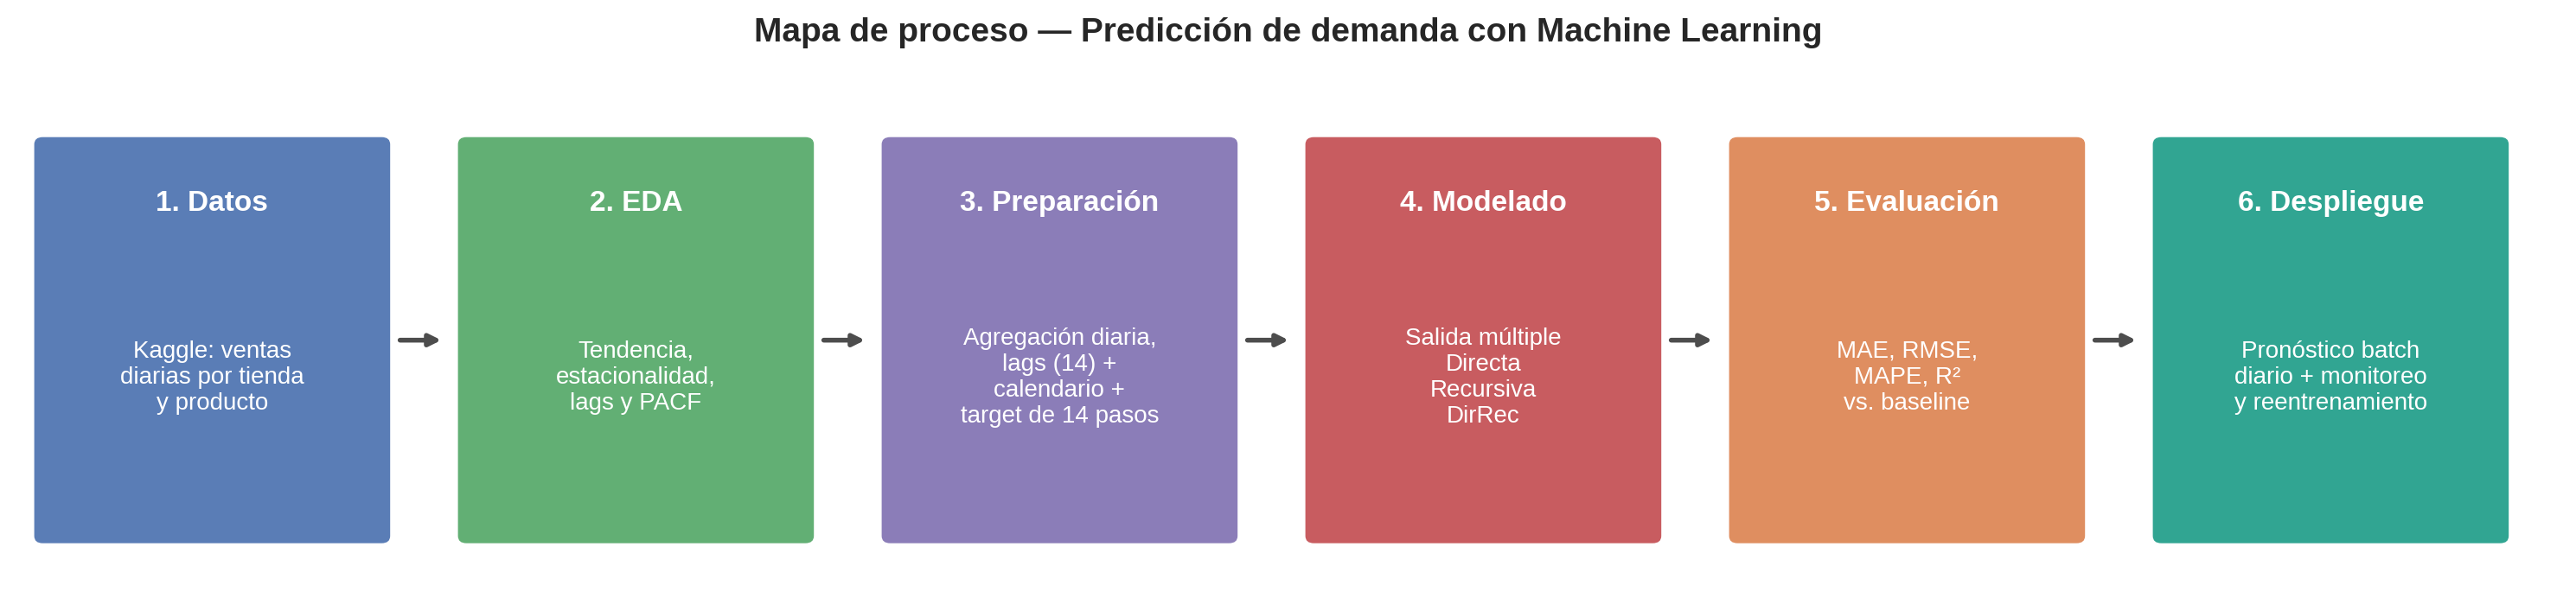

In [ ]:
# Mapa de proceso del proyecto
etapas = [
    ("1. Datos", "Kaggle: ventas\ndiarias por tienda\ny producto"),
    ("2. EDA", "Tendencia,\nestacionalidad,\nlags y PACF"),
    ("3. Preparación", "Agregación diaria,\nlags (14) +\ncalendario +\ntarget de 14 pasos"),
    ("4. Modelado", "Salida múltiple\nDirecta\nRecursiva\nDirRec"),
    ("5. Evaluación", "MAE, RMSE,\nMAPE, R²\nvs. baseline"),
    ("6. Despliegue", "Pronóstico batch\ndiario + monitoreo\ny reentrenamiento"),
]
colores = ["#4C72B0", "#55A868", "#8172B2", "#C44E52", "#DD8452", "#1F9E89"]

fig, ax = plt.subplots(figsize=(15, 3.6))
ax.set_xlim(0, 6 * 2.5); ax.set_ylim(0, 3.6); ax.axis("off")
for i, ((titulo, detalle), c) in enumerate(zip(etapas, colores)):
    x = i * 2.5 + 0.15
    ax.add_patch(FancyBboxPatch((x, 0.35), 2.0, 2.7, boxstyle="round,pad=0.05",
                                fc=c, ec="none", alpha=0.92))
    ax.text(x + 1.0, 2.65, titulo, ha="center", va="center", color="white",
            fontsize=12, fontweight="bold")
    ax.text(x + 1.0, 1.45, detalle, ha="center", va="center", color="white", fontsize=10)
    if i < len(etapas) - 1:
        ax.annotate("", xy=(x + 2.38, 1.7), xytext=(x + 2.08, 1.7),
                    arrowprops=dict(arrowstyle="-|>", color="0.3", lw=2))
ax.set_title("Mapa de proceso — Predicción de demanda con Machine Learning", fontsize=14)
plt.show()

**¿Qué muestra el mapa?** Son las seis etapas que seguimos en el proyecto. La etapa clave es la 3: ahí la serie de tiempo se convierte en un problema de regresión supervisada (X = lags + calendario, y = los 14 días siguientes). Todo lo que viene después (las 4 estrategias, la evaluación y el despliegue) parte de esas mismas matrices.

# 2. Carga y comprensión de los datos

## 2.1 Dataset utilizado
>

| Campo | Detalle |
|---|---|
| **Nombre** | Store Item Demand Forecasting Challenge |
| **Fuente** | Kaggle (competencia *Getting Started / Playground*) |
| **Enlace original** | https://www.kaggle.com/competitions/demand-forecasting-kernels-only/data |
| **Archivo usado** | `train.csv` |
| **Periodo** | 01/01/2013 – 31/12/2017 (5 años, diario) |
| **Tamaño** | 913 000 filas × 4 columnas |
| **Granularidad** | 10 tiendas × 50 productos = 500 series diarias |
>
**Columnas:**
- `date`: fecha de la venta.
- `store`: identificador de la tienda (1 a 10).
- `item`: identificador del producto (1 a 50).
- `sales`: unidades vendidas ese día (nuestra **demanda**).

**¿Qué problema permite abordar?**
>
 Es un dataset pensado justamente para *demand forecasting*: ventas históricas diarias sin huecos, con tendencia y estacionalidad marcadas, lo que permite practicar pronóstico multipaso con lags.



In [ ]:
RUTA_LOCAL = "train.csv"   # archivo descargado de Kaggle y subido a Colab
URL_COPIA = "https://raw.githubusercontent.com/panambY/Store_Item_Demand/master/data/train.csv"

fuente = RUTA_LOCAL if os.path.exists(RUTA_LOCAL) else URL_COPIA
df = pd.read_csv(fuente, parse_dates=["date"])
print("Datos leídos desde:", fuente)
df.head()

Datos leídos desde: https://raw.githubusercontent.com/panambY/Store_Item_Demand/master/data/train.csv


,date,store,item,sales
0,2013-01-01,1,1,13
1,2013-01-02,1,1,11
2,2013-01-03,1,1,14
3,2013-01-04,1,1,13
4,2013-01-05,1,1,10


**Interpretación:** cada fila indica cuántas unidades vendió un producto en una tienda en un día específico. Por ejemplo, el 01/01/2013 la tienda 1 vendió 13 unidades del producto 1. Es la granularidad más fina del dataset.

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 913000 entries, 0 to 912999
Data columns (total 4 columns):
 #   Column  Non-Null Count   Dtype         
---  ------  --------------   -----         
 0   date    913000 non-null  datetime64[ns]
 1   store   913000 non-null  int64         
 2   item    913000 non-null  int64         
 3   sales   913000 non-null  int64         
dtypes: datetime64[ns](1), int64(3)
memory usage: 27.9 MB


**Interpretación:** son 913 000 registros y ninguna columna tiene nulos. La fecha ya se cargó como `datetime64` y el resto son enteros, así que no hace falta ninguna conversión de tipos.

In [ ]:
print("Rango de fechas :", df["date"].min().date(), "→", df["date"].max().date())
print("Días distintos  :", df["date"].nunique())
print("Tiendas         :", df["store"].nunique())
print("Productos       :", df["item"].nunique())
print("Valores nulos   :", int(df.isna().sum().sum()))
print("Filas duplicadas:", int(df.duplicated(subset=["date", "store", "item"]).sum()))
print("Registros por combinación tienda-producto:", df.groupby(["store", "item"]).size().unique())

Rango de fechas : 2013-01-01 → 2017-12-31
Días distintos  : 1826
Tiendas         : 10
Productos       : 50
Valores nulos   : 0
Filas duplicadas: 0
Registros por combinación tienda-producto: [1826]


**Interpretación:** los datos están completos: 1826 días seguidos (5 años), 10 tiendas y 50 productos, sin nulos ni duplicados, y **cada una de las 500 combinaciones tienda-producto tiene exactamente 1826 registros**. Eso significa que no hay días faltantes, algo importante para trabajar con lags porque un hueco movería todos los retardos.

In [ ]:
df["sales"].describe()

,sales
count,"913,000.00"
mean,52.25
std,28.80
min,0.00
25%,30.00
50%,47.00
75%,70.00
max,231.00


**Interpretación:** en promedio un producto vende unas 52 unidades diarias por tienda, con un máximo de 231. Hay algunos ceros (mínimo = 0), que son días sin venta de un producto puntual y no errores. La dispersión (desviación de 28.8) confirma que hay productos y tiendas con volúmenes muy distintos.

# 3. EDA: Análisis exploratorio de datos

Como el objetivo es pronosticar la **demanda total de la cadena**, primero agregamos las ventas de las 10 tiendas y los 50 productos por día. Luego revisamos, en este orden: **tendencia → estacionalidad → ciclos/dependencia serial (lags)**.

In [ ]:
# Demanda diaria total de la cadena (suma de todas las tiendas y productos)
demanda = df.groupby("date")["sales"].sum().asfreq("D")
demanda.name = "demanda"
print("Días:", len(demanda), "| nulos tras asfreq('D'):", demanda.isna().sum())
demanda.head()

Días: 1826 | nulos tras asfreq('D'): 0


,demanda
date,
2013-01-01,13696
2013-01-02,13678
2013-01-03,14488
2013-01-04,15677
2013-01-05,16237


**Interpretación:** al sumar todas las tiendas y productos queda **una serie diaria de 1826 puntos** sin huecos. Esta es la variable objetivo del proyecto: la demanda total de la cadena. Los primeros días de enero de 2013 rondan las 13 000–16 000 unidades.

## 3.1 Evolución de la demanda y tendencia (media móvil de 365 días)

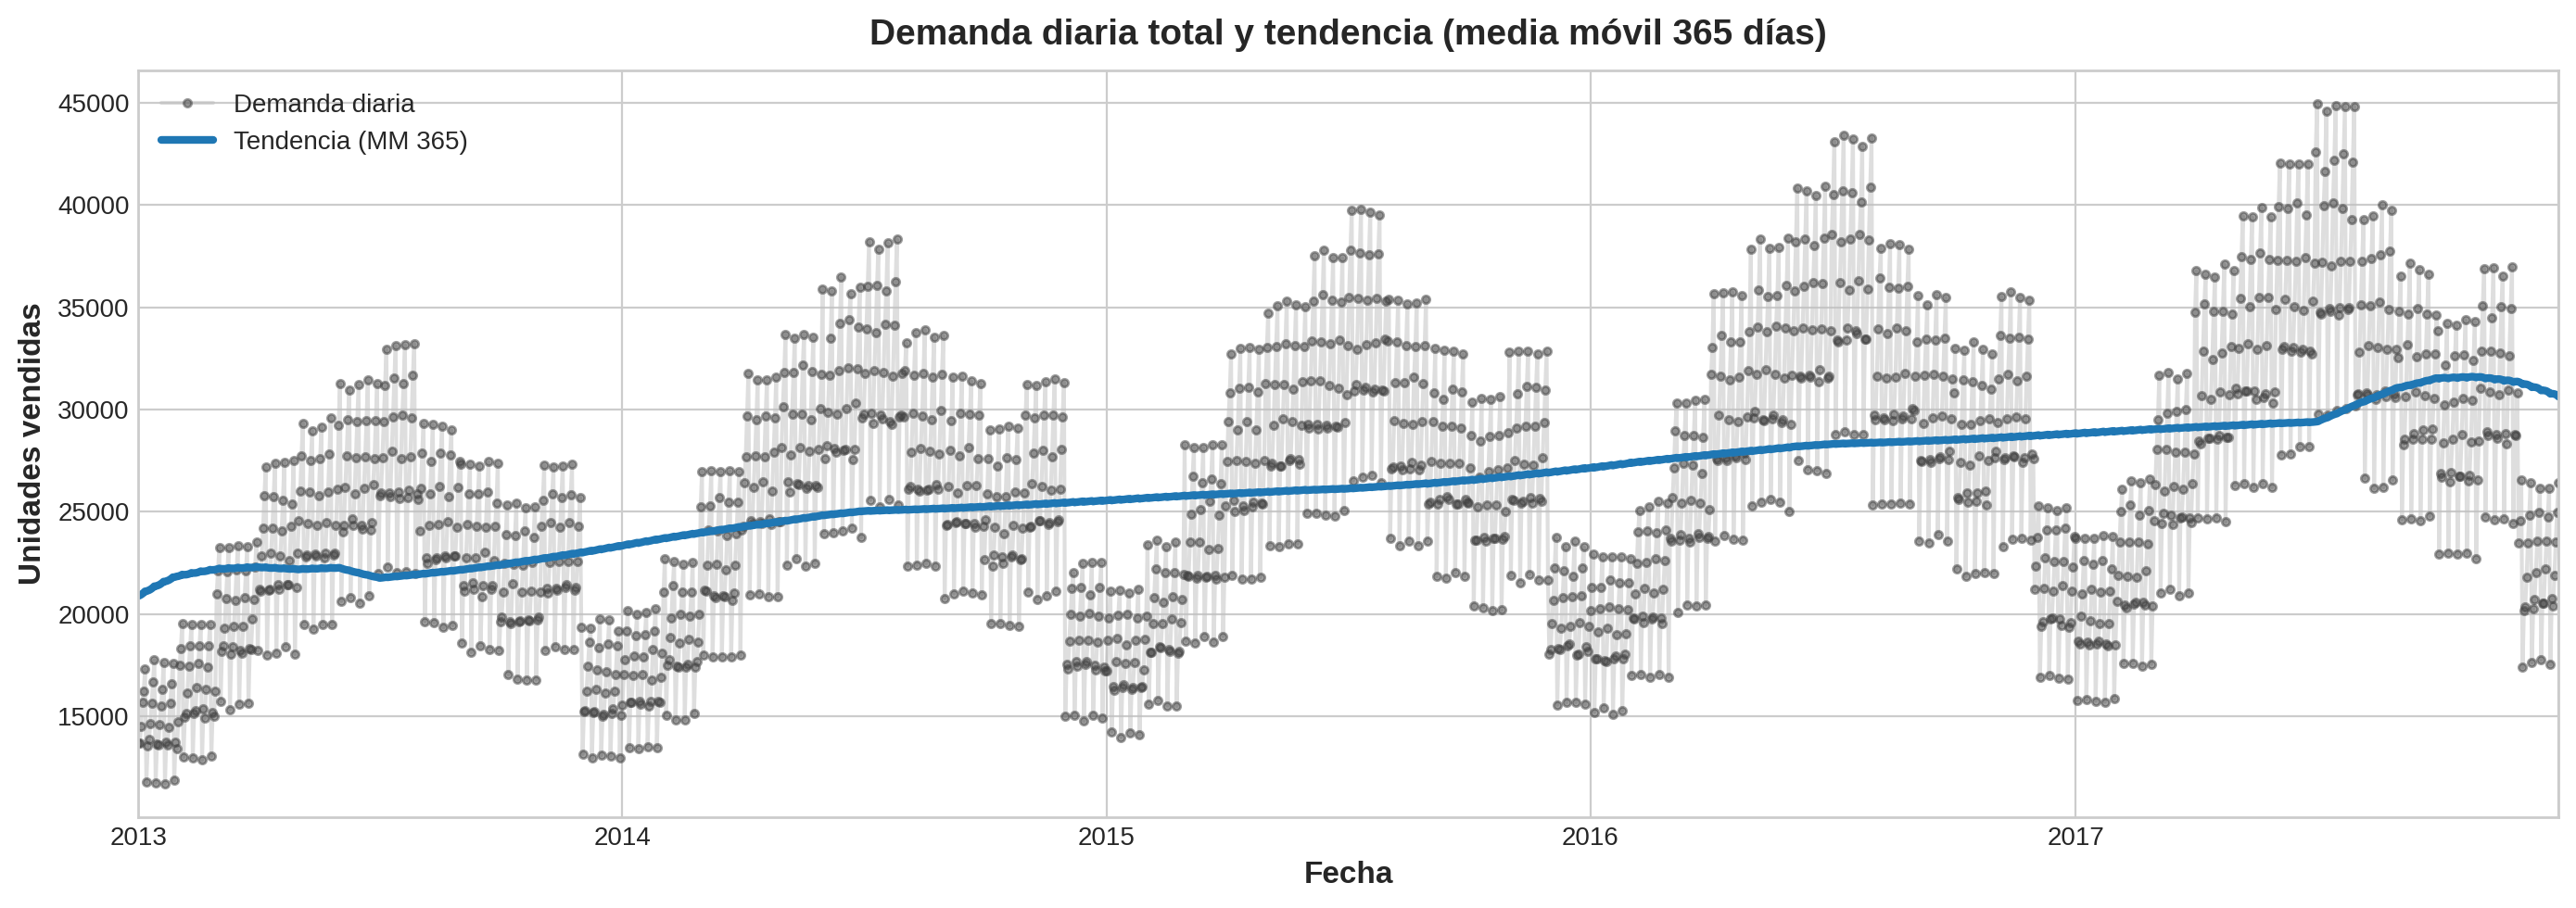

In [ ]:
tendencia = demanda.rolling(window=365, center=True, min_periods=183).mean()

ax = demanda.plot(**plot_params, alpha=0.5, figsize=(14, 5),
                  title="Demanda diaria total y tendencia (media móvil 365 días)")
tendencia.plot(ax=ax, linewidth=3, color="C0", label="Tendencia (MM 365)")
ax.set_ylabel("Unidades vendidas"); ax.set_xlabel("Fecha")
ax.legend(["Demanda diaria", "Tendencia (MM 365)"]);

**Interpretación:** la línea azul (media móvil de 365 días) muestra una **tendencia creciente**, más marcada entre 2013 y 2014 y que luego sigue subiendo pero más despacio. En gris se nota además un "sube y baja" que se repite cada año (picos a mitad de año y caídas en diciembre-enero) y una banda gruesa por la variación entre días de la semana. O sea, la serie tiene tendencia y estacionalidad al mismo tiempo.

,unidades,crecimiento_%
date,,
2013,7941243,NaN
2014,9135482,15.04
2015,9536887,4.39
2016,10357160,8.60
2017,10733740,3.64


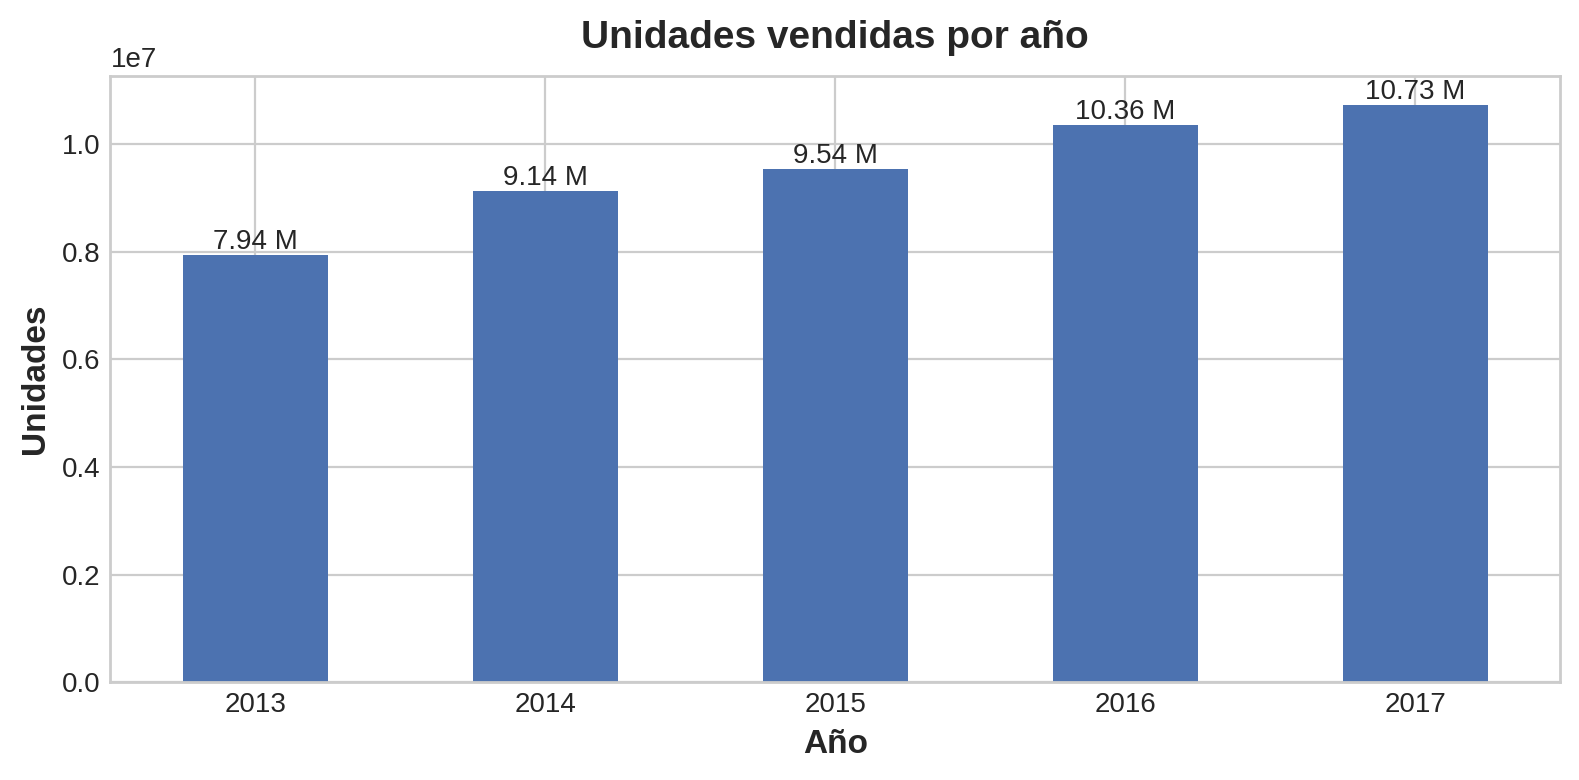

In [ ]:
anual = demanda.groupby(demanda.index.year).sum()
crec = anual.pct_change() * 100
resumen_anual = pd.DataFrame({"unidades": anual, "crecimiento_%": crec})
display(resumen_anual)

ax = anual.plot(kind="bar", color="#4C72B0", figsize=(8, 4), title="Unidades vendidas por año")
for p, v in zip(ax.patches, anual.values):
    ax.annotate(f"{v/1e6:.2f} M", (p.get_x() + p.get_width()/2, v), ha="center", va="bottom")
ax.set_xlabel("Año"); ax.set_ylabel("Unidades"); plt.xticks(rotation=0);

**Interpretación:** la demanda pasó de 7.94 millones de unidades en 2013 a 10.73 millones en 2017. El mayor salto fue en 2014 (+15 %) y luego el crecimiento se modera (entre +3.6 % y +8.6 %). Esto confirma lo que se veía en la media móvil: el negocio crece, pero cada vez a un ritmo menor.

## 3.2 Estacionalidad semanal y anual

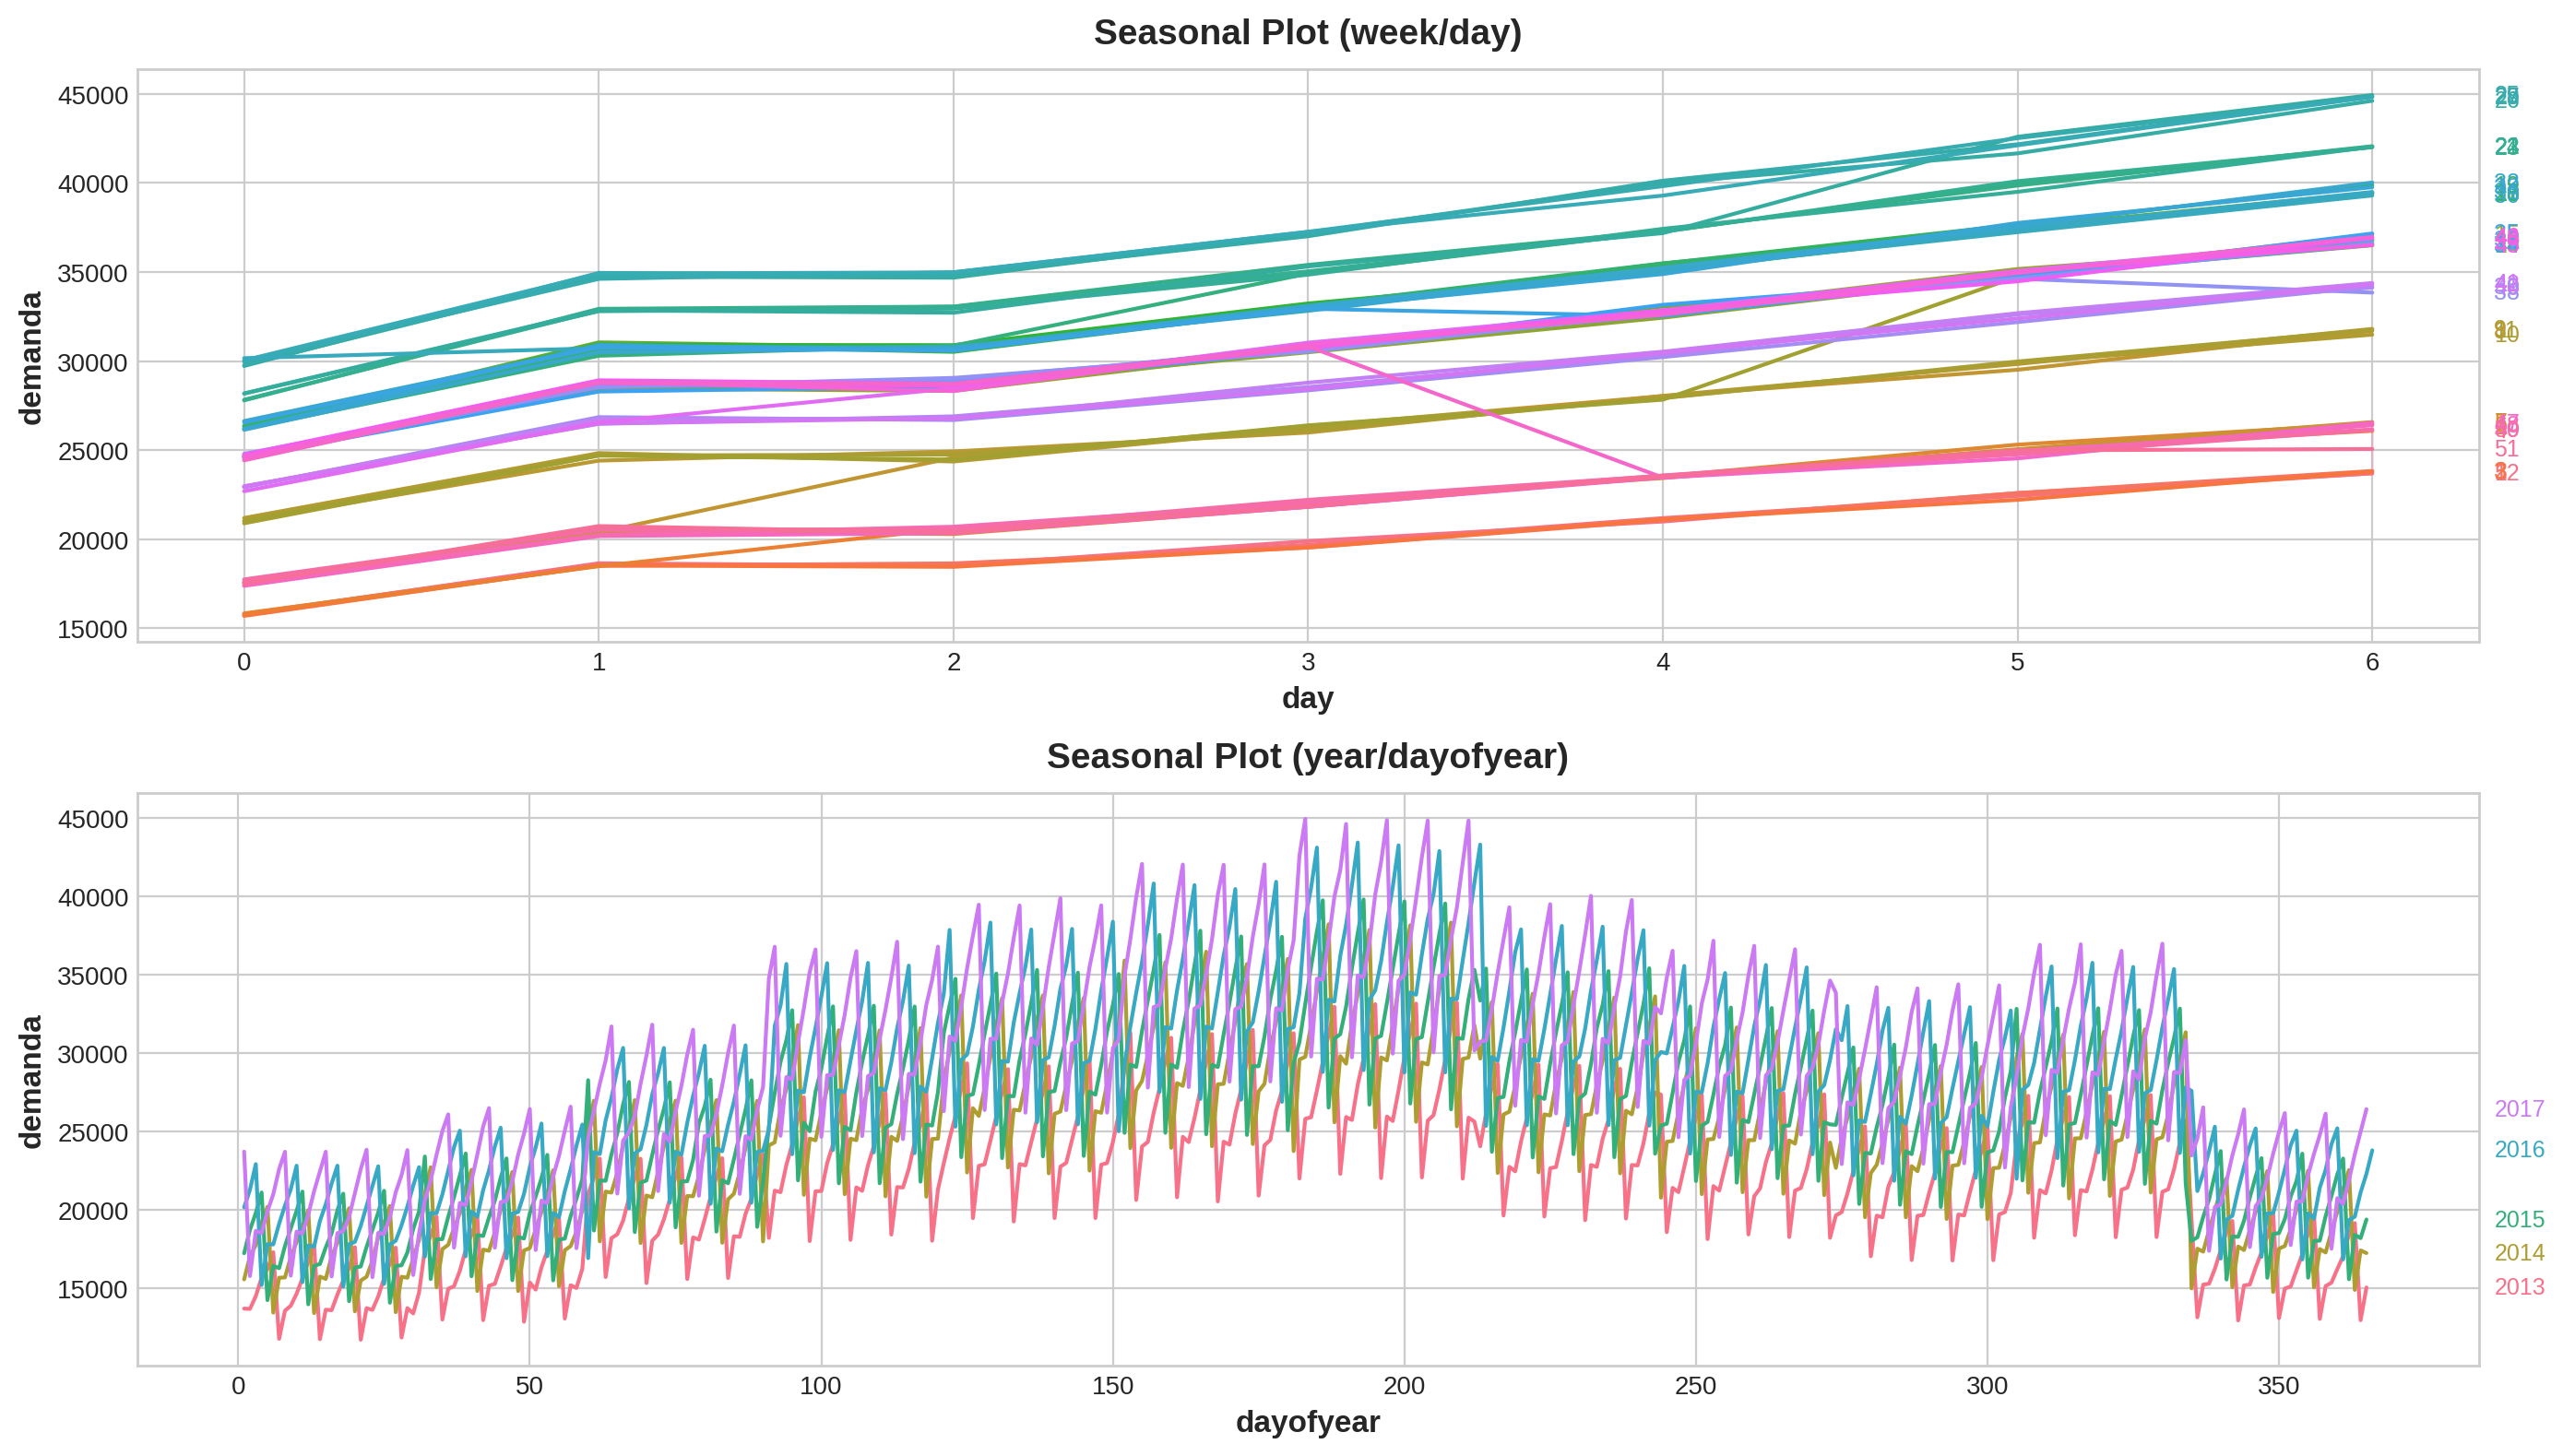

In [ ]:
def seasonal_plot(X, y, period, freq, ax=None):
    if ax is None:
        _, ax = plt.subplots()
    palette = sns.color_palette("husl", n_colors=X[period].nunique())
    ax = sns.lineplot(x=freq, y=y, hue=period, data=X, ax=ax, palette=palette, legend=False)
    ax.set_title(f"Seasonal Plot ({period}/{freq})")
    for line, name in zip(ax.lines, X[period].unique()):
        y_ = line.get_ydata()[-1]
        ax.annotate(name, xy=(1, y_), xytext=(6, 0), color=line.get_color(),
                    xycoords=ax.get_yaxis_transform(), textcoords="offset points",
                    size=9, va="center")
    return ax

X_season = demanda.to_frame()
X_season["week"] = X_season.index.isocalendar().week.astype(int)
X_season["day"] = X_season.index.dayofweek          # 0 = lunes, 6 = domingo
X_season["year"] = X_season.index.year
X_season["dayofyear"] = X_season.index.dayofyear

fig, (ax0, ax1) = plt.subplots(2, 1, figsize=(14, 8))
seasonal_plot(X_season[X_season.year == 2017], y="demanda", period="week", freq="day", ax=ax0)
seasonal_plot(X_season, y="demanda", period="year", freq="dayofyear", ax=ax1);

**Interpretación:**
- **Arriba (semanas de 2017, día 0 = lunes y 6 = domingo):** todas las semanas tienen la misma forma: el lunes es el día más bajo y la demanda sube hasta el domingo. Lo que cambia entre semanas es el "nivel", según la época del año.
- **Abajo (cada línea es un año):** los 5 años siguen el mismo patrón anual: bajo en enero-febrero, sube hasta un pico en julio (días 180–210) y cae fuerte a fines de noviembre/diciembre. Además cada año está un poco más arriba que el anterior (la tendencia).

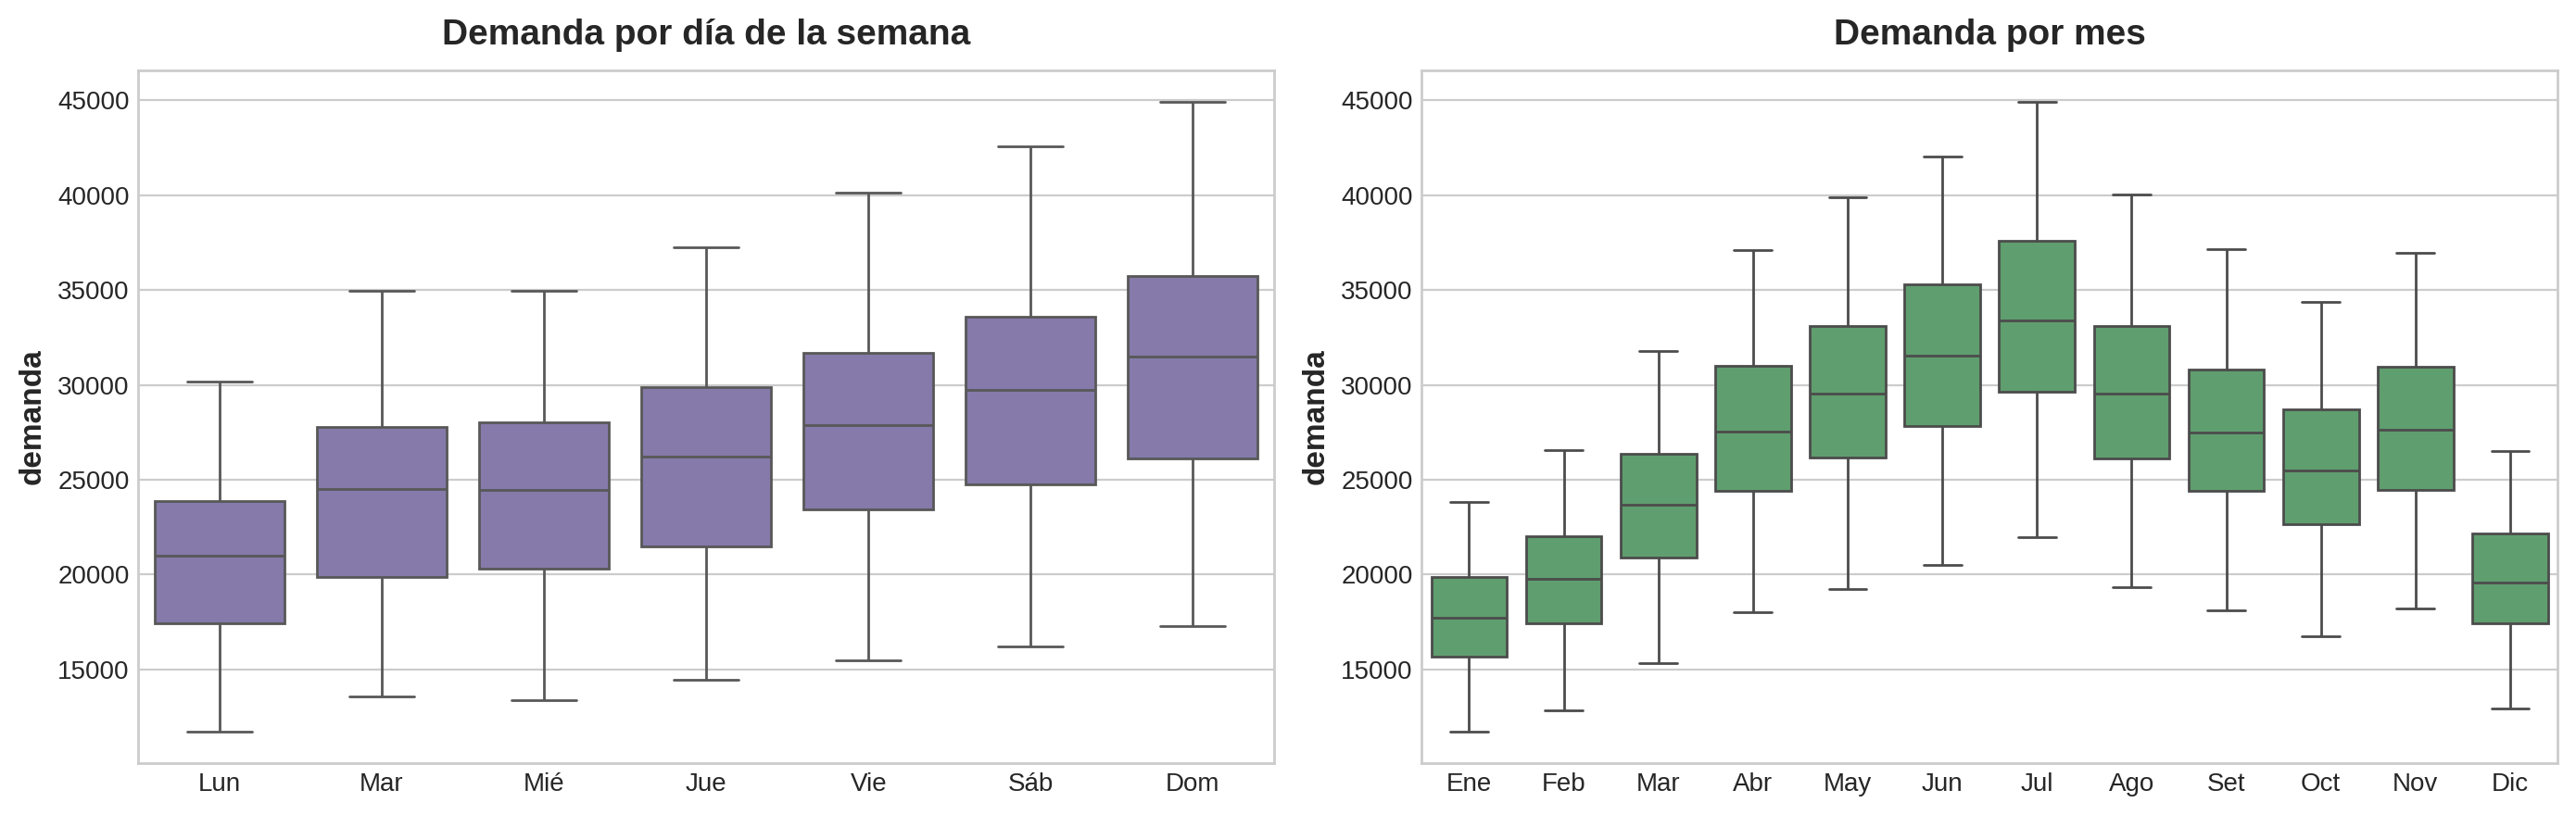

Demanda promedio por día: {'Lun': 20715, 'Mar': 24113, 'Mié': 24184, 'Jue': 25862, 'Vie': 27579, 'Sáb': 29331, 'Dom': 31072}
El domingo vende 50.0% más que el lunes


In [ ]:
dias = ["Lun", "Mar", "Mié", "Jue", "Vie", "Sáb", "Dom"]
meses = ["Ene", "Feb", "Mar", "Abr", "May", "Jun", "Jul", "Ago", "Set", "Oct", "Nov", "Dic"]

fig, (ax0, ax1) = plt.subplots(1, 2, figsize=(14, 4.5))
sns.boxplot(x=X_season["day"], y=X_season["demanda"], ax=ax0, color="#8172B2")
ax0.set_xticklabels(dias); ax0.set_title("Demanda por día de la semana"); ax0.set_xlabel("")
sns.boxplot(x=X_season.index.month, y=X_season["demanda"], ax=ax1, color="#55A868")
ax1.set_xticklabels(meses); ax1.set_title("Demanda por mes"); ax1.set_xlabel("")
plt.show()

prom_dia = X_season.groupby("day")["demanda"].mean()
print("Demanda promedio por día:", dict(zip(dias, prom_dia.round(0).astype(int))))
print(f"El domingo vende {prom_dia[6]/prom_dia[0]-1:.1%} más que el lunes")

**Interpretación:** el día de la semana es el efecto más fuerte de la serie: **el domingo se vende en promedio 50 % más que el lunes** (31 072 vs. 20 715 unidades). Por meses, julio es el más alto y enero, febrero y diciembre los más bajos. Estas dos estacionalidades (semanal y anual) son las que el modelo tiene que aprender, por eso agregamos variables de día de la semana y términos de Fourier anuales.

## 3.3 Descomposición aditiva

$$Y_t = Tendencia + Estacionalidad + Residuo$$

Usamos `seasonal_decompose` con periodo 7 (estacionalidad semanal).

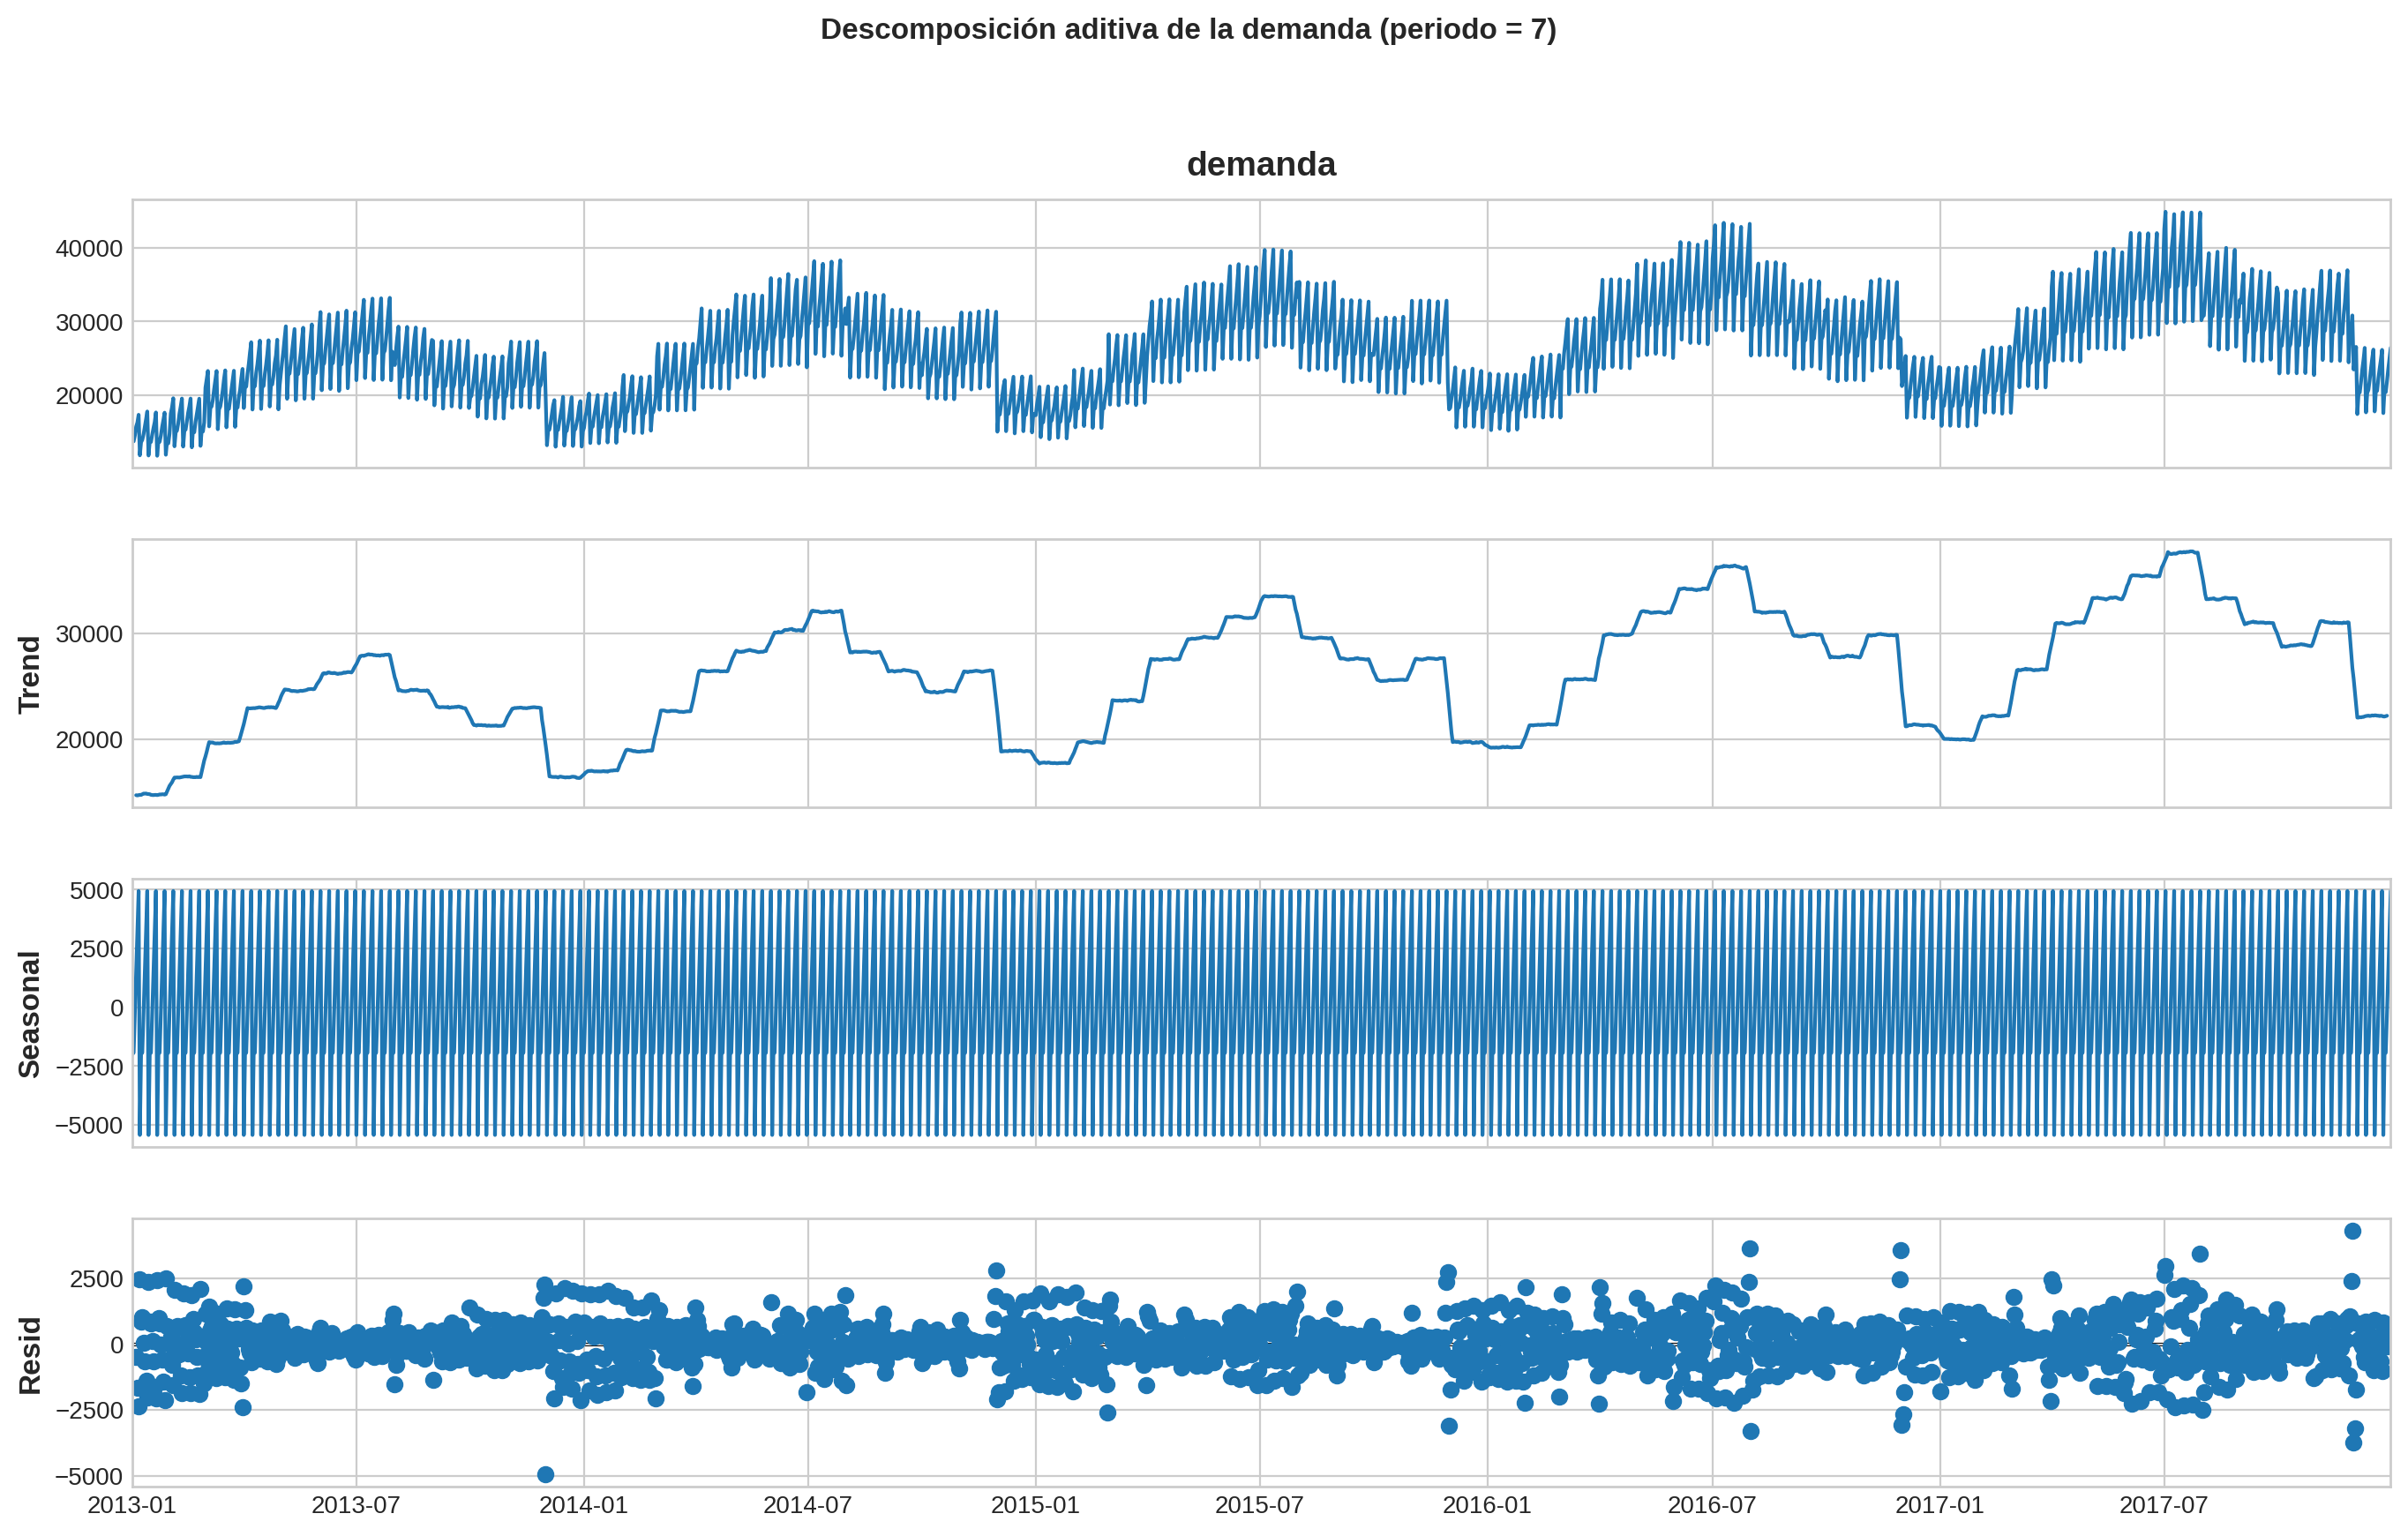

In [ ]:
from statsmodels.tsa.seasonal import seasonal_decompose

descomp = seasonal_decompose(demanda, model="additive", period=7)
fig = descomp.plot()
fig.set_size_inches(14, 9)
fig.suptitle("Descomposición aditiva de la demanda (periodo = 7)", fontweight="bold", y=1.01)
plt.show()

**Interpretación:** la descomposición separa la serie en tres partes:
- **Trend:** ya sin el efecto semanal, se ve la ola anual (sube hasta julio y baja a fin de año) montada sobre un crecimiento año a año. Algo que llama la atención es que la tendencia avanza **en escalones que cambian al inicio de cada mes**: el nivel de ventas se mantiene casi fijo dentro del mes y salta al pasar al siguiente.
- **Seasonal:** el patrón semanal (±5 000 unidades) es muy estable y se repite igual durante los 5 años.
- **Resid:** los residuos quedan alrededor de cero y son chicos frente al nivel de la serie; los más grandes caen justo en los cambios de mes. Es una serie bastante "limpia" y predecible.

## 3.4 Periodograma

El periodograma confirma de forma estadística cuáles son los ciclos dominantes (anual, semestral, mensual, semanal, etc.).

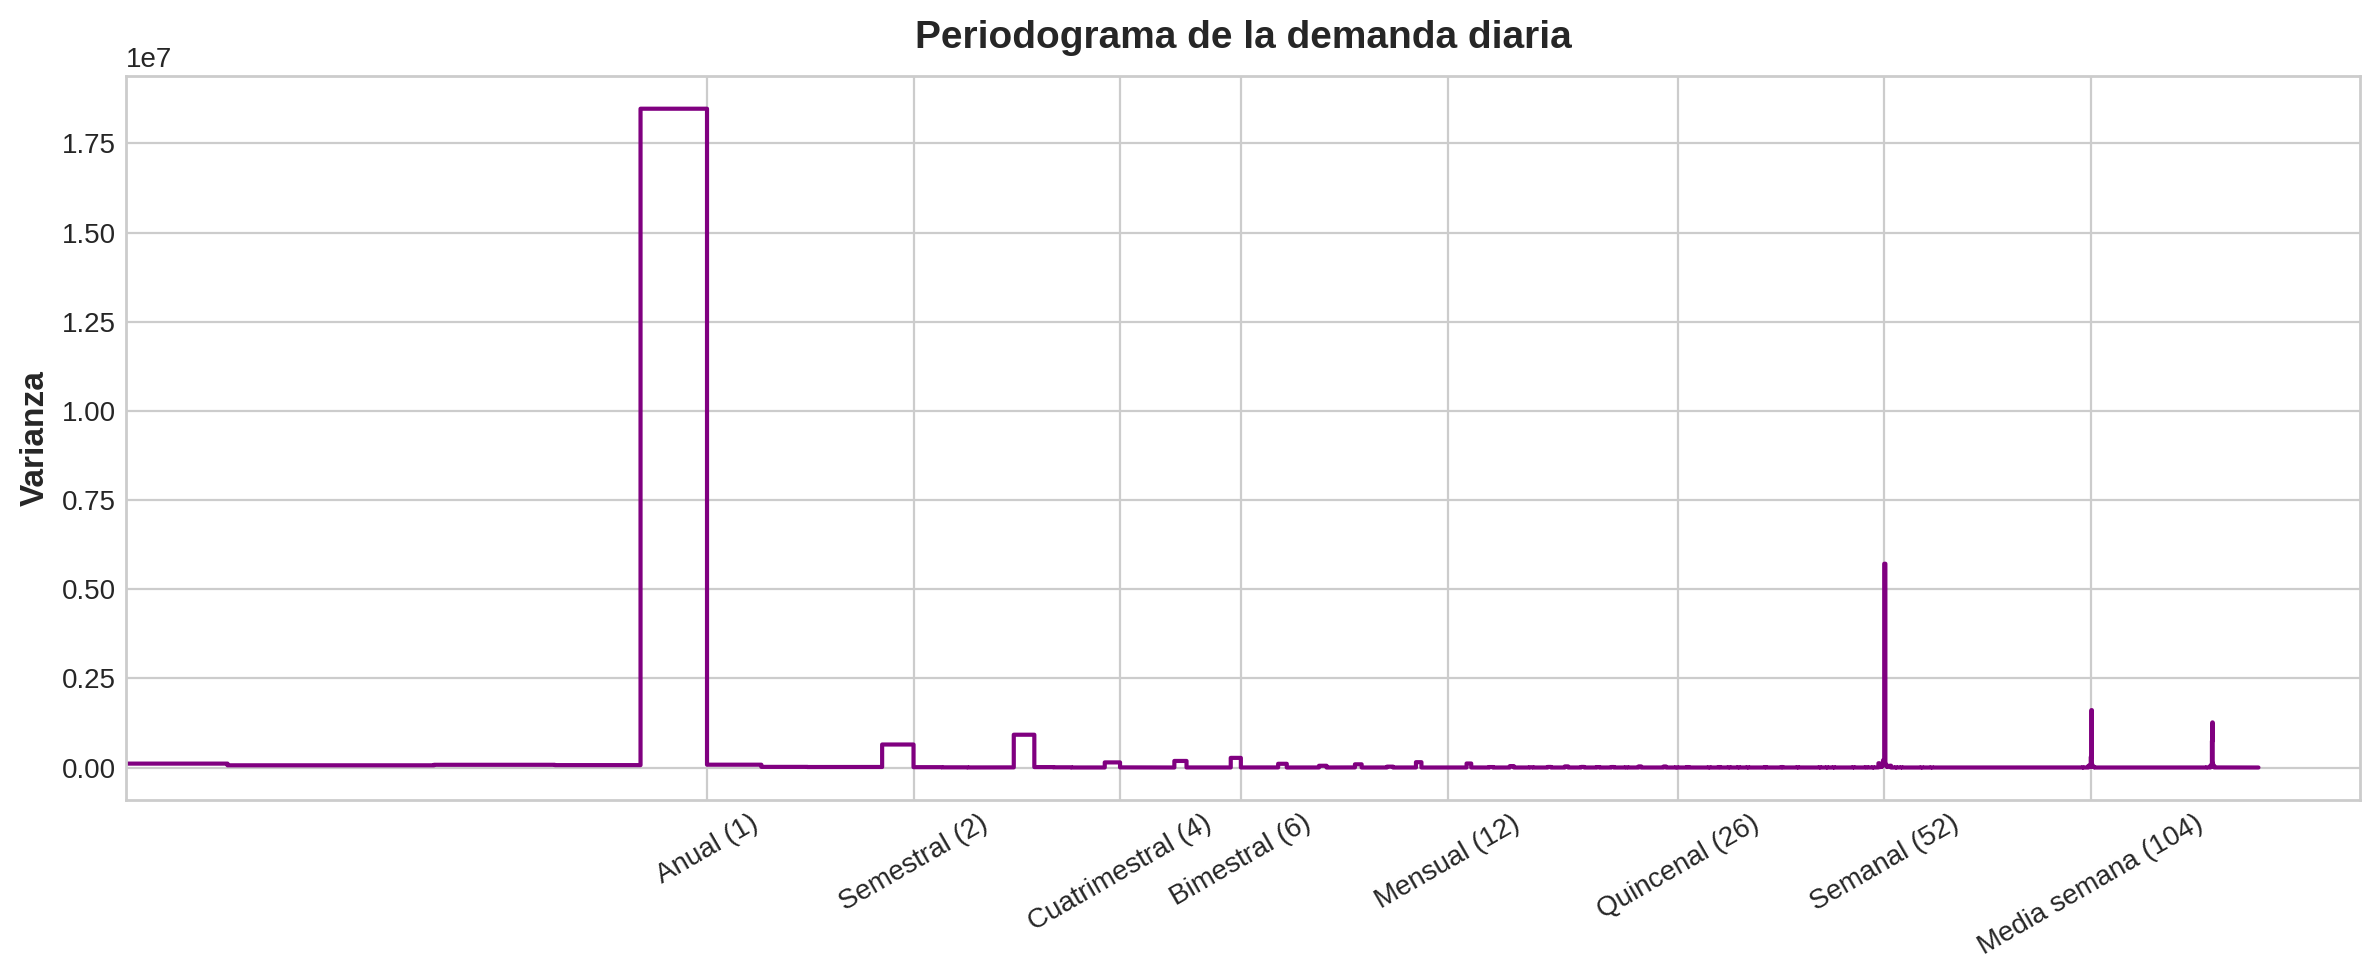

In [ ]:
from scipy.signal import periodogram

def plot_periodogram(ts, detrend="linear", ax=None):
    fs = pd.Timedelta("365D") / pd.Timedelta("1D")
    frequencies, spectrum = periodogram(ts, fs=fs, detrend=detrend,
                                        window="boxcar", scaling="spectrum")
    if ax is None:
        _, ax = plt.subplots(figsize=(12, 5))
    ax.step(frequencies, spectrum, color="purple")
    ax.set_xscale("log")
    ax.set_xticks([1, 2, 4, 6, 12, 26, 52, 104])
    ax.set_xticklabels(["Anual (1)", "Semestral (2)", "Cuatrimestral (4)", "Bimestral (6)",
                        "Mensual (12)", "Quincenal (26)", "Semanal (52)", "Media semana (104)"],
                       rotation=30)
    ax.ticklabel_format(axis="y", style="sci", scilimits=(0, 0))
    ax.set_ylabel("Varianza"); ax.set_title("Periodograma de la demanda diaria")
    return ax

plot_periodogram(demanda);

**Interpretación:** el pico más alto está en la frecuencia **anual (1)**, así que el ciclo del año es el componente que más varianza explica. El segundo pico está en **semanal (52)**, y aparecen picos más chicos en media semana (104) y más allá, que son los "armónicos" de la forma semanal (el patrón no es una onda perfecta). No se ven picos mensuales ni quincenales importantes, así que no hace falta modelar ciclos de pago. Por eso usamos **dummies de día de la semana + Fourier anual**.

## 3.5 Dependencia serial: gráficos de lag y autocorrelación parcial (PACF)

Un **lag** es el valor pasado de la misma serie. Si hay correlación fuerte entre la demanda de hoy y la de días anteriores, los lags sirven como variables para el modelo.

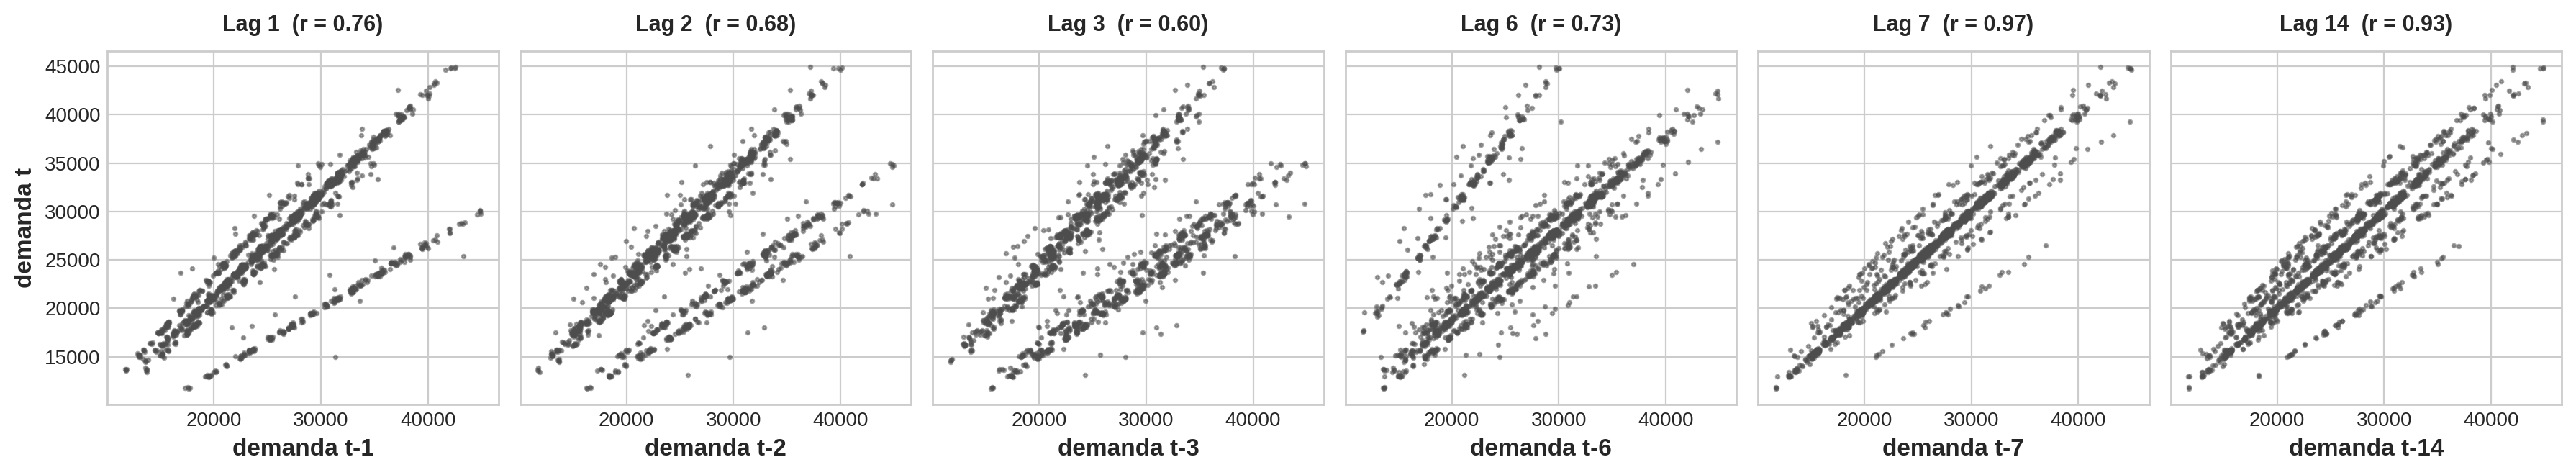

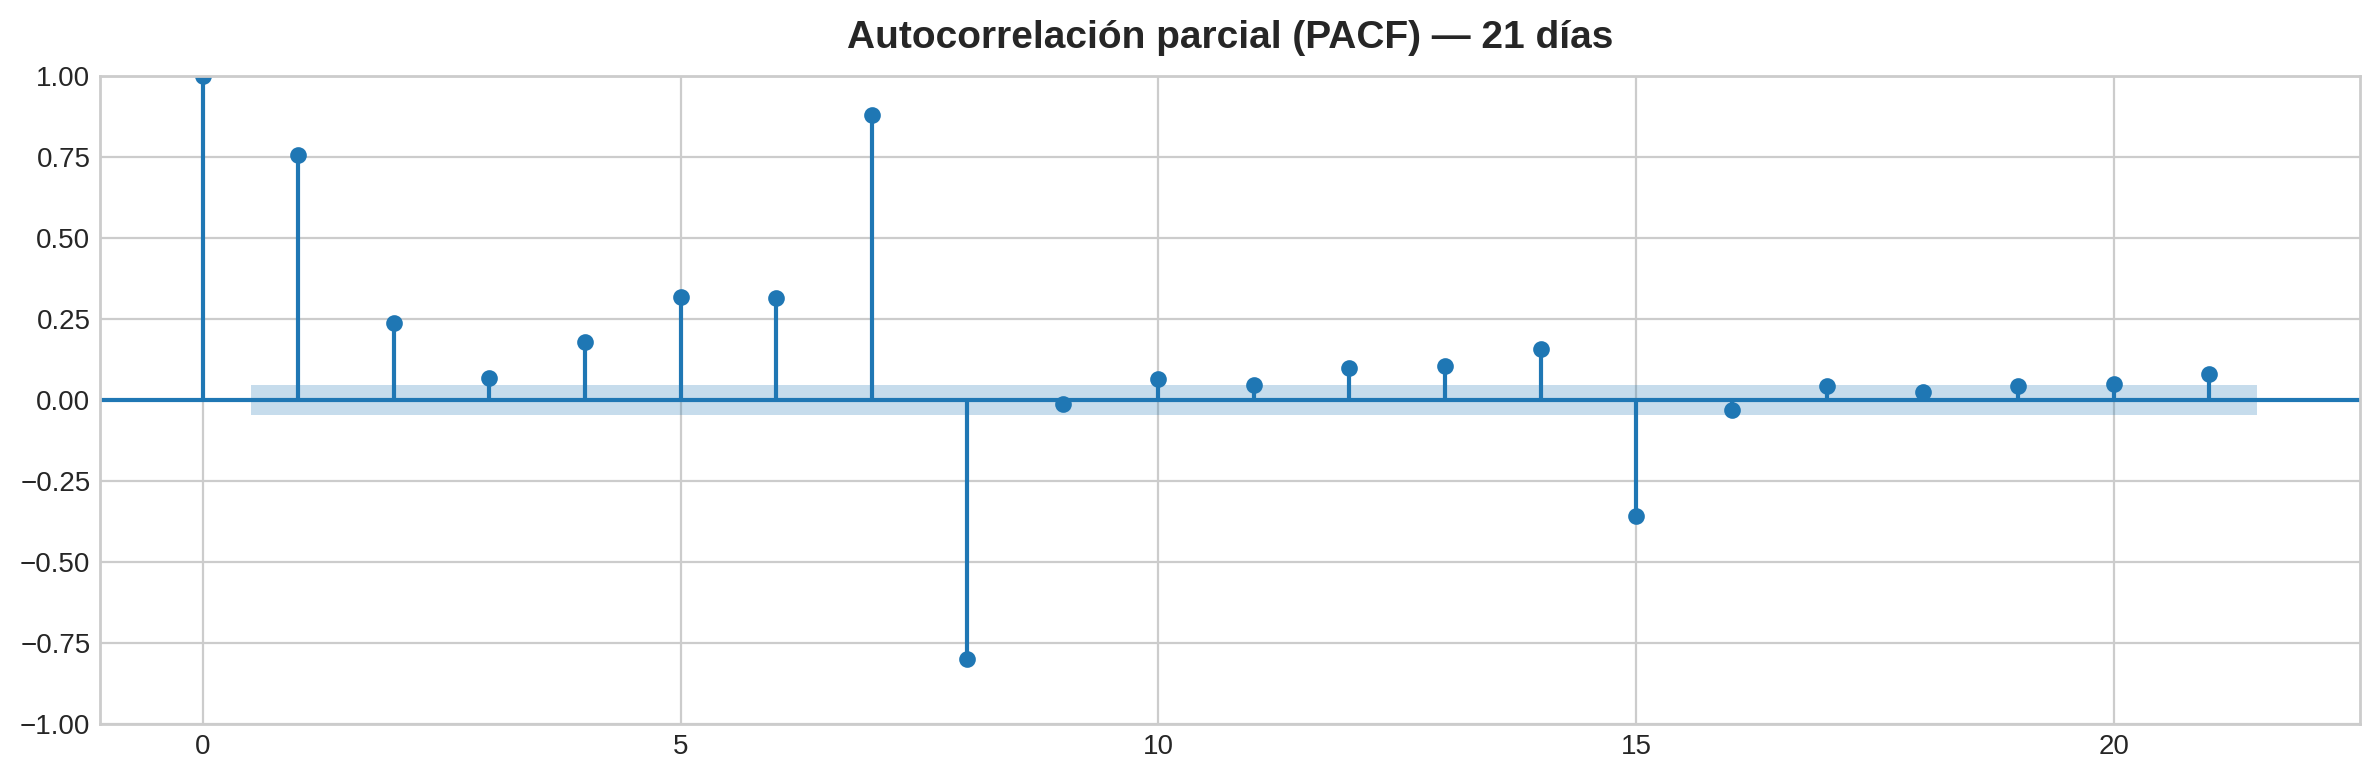

In [ ]:
from statsmodels.graphics.tsaplots import plot_pacf

lags_revisar = [1, 2, 3, 6, 7, 14]
fig, axs = plt.subplots(1, 6, figsize=(18, 3.4), sharey=True)
for ax, k in zip(axs, lags_revisar):
    x_ = demanda.shift(k)
    corr = demanda.corr(x_)
    ax.scatter(x_, demanda, s=3, alpha=0.5, color="0.3")
    ax.set_title(f"Lag {k}  (r = {corr:.2f})", fontsize=11)
    ax.set_xlabel(f"demanda t-{k}")
axs[0].set_ylabel("demanda t")
plt.show()

fig, ax = plt.subplots(figsize=(12, 4))
plot_pacf(demanda, lags=21, ax=ax, method="ywm")
ax.set_title("Autocorrelación parcial (PACF) — 21 días");

**Interpretación:**
- En los gráficos de lag, la correlación más fuerte es con el **lag 7 (r = 0.97)** y el **lag 14 (r = 0.93)**: la demanda de hoy se parece muchísimo a la del mismo día de la semana anterior. El lag 1 tiene r = 0.76 y se ven dos "nubes" porque cuando se pasa de domingo a lunes hay una caída fuerte.
- En el **PACF** (autocorrelación parcial), los lags 1 y 7 son los más altos y hay otros significativos hasta el 14–15 (fuera de la franja azul).

Por eso usamos **14 lags** (dos semanas de historia) como variables del modelo.

## 3.6 Demanda por tienda y por producto

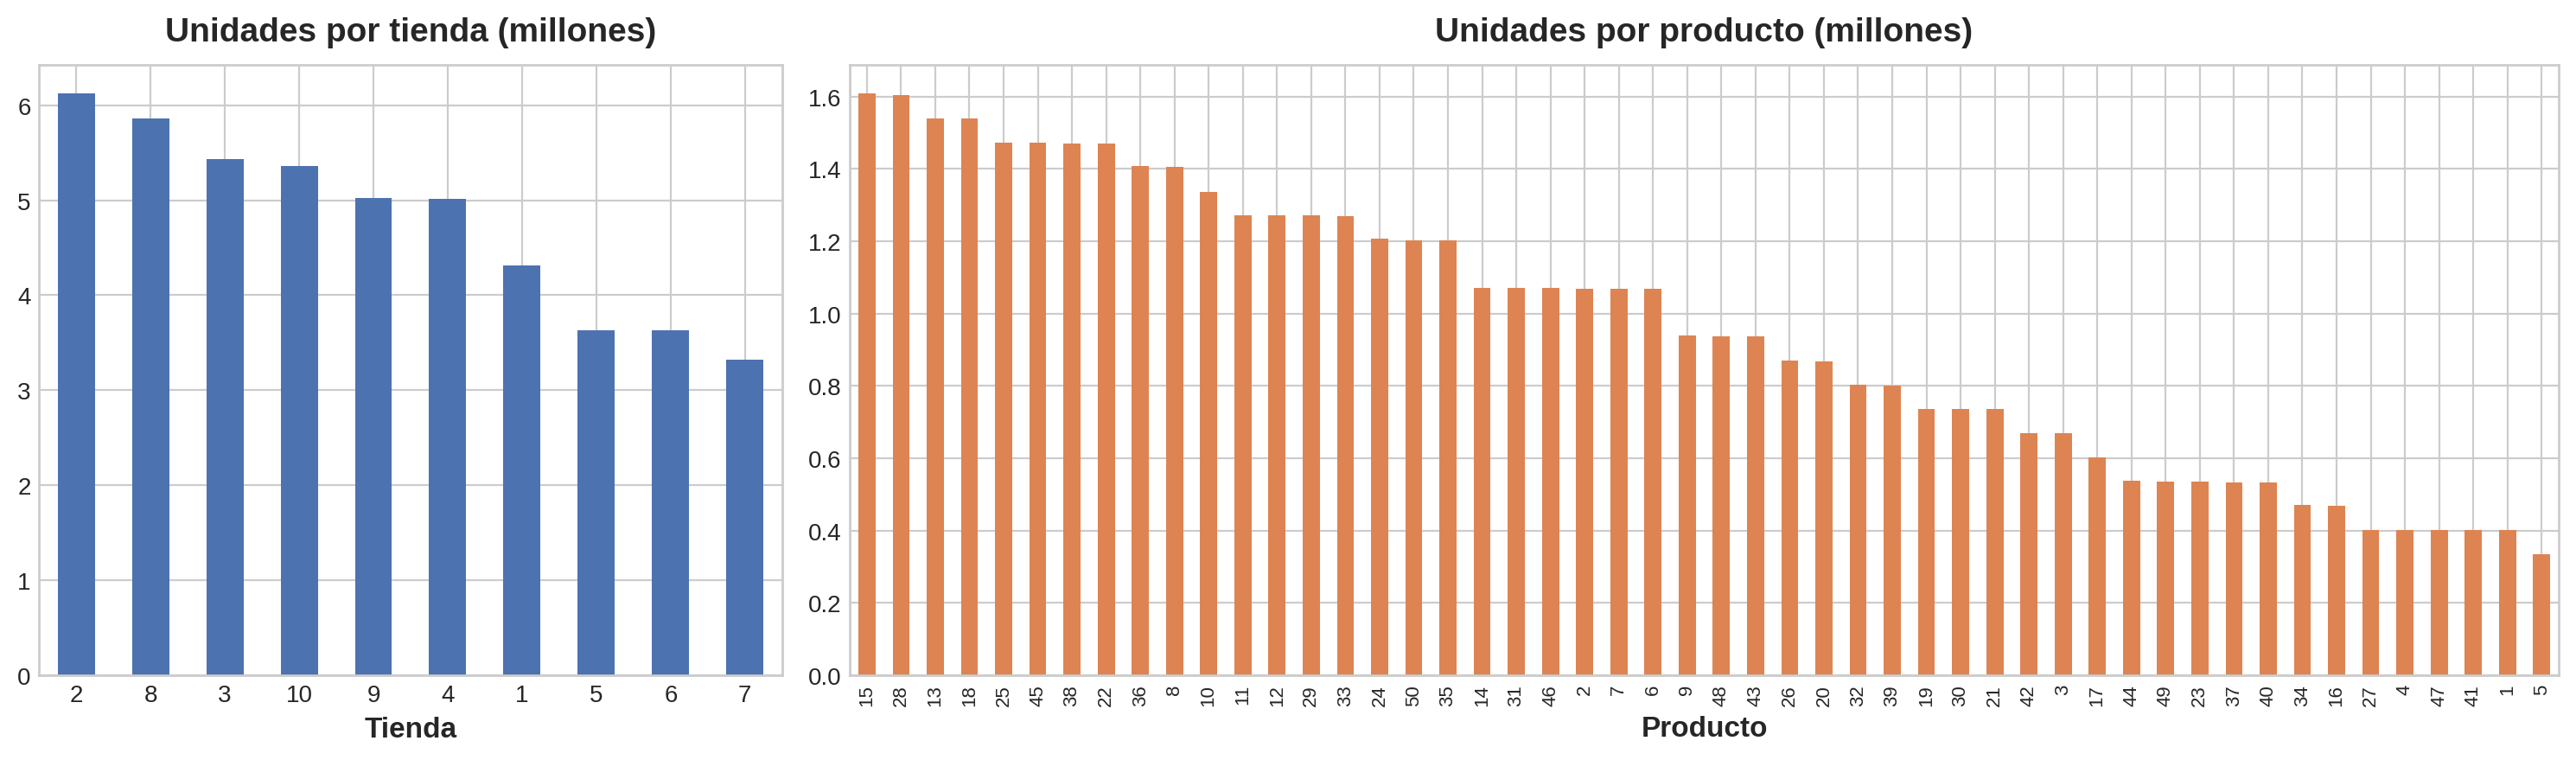

Top 3 tiendas concentran el 36.5% de la demanda
Top 10 productos concentran el 31.4% de la demanda


In [ ]:
por_tienda = df.groupby("store")["sales"].sum().sort_values(ascending=False)
por_item = df.groupby("item")["sales"].sum().sort_values(ascending=False)

fig, (ax0, ax1) = plt.subplots(1, 2, figsize=(15, 4.5), gridspec_kw=dict(width_ratios=[1, 2.3]))
(por_tienda / 1e6).plot(kind="bar", ax=ax0, color="#4C72B0")
ax0.set_title("Unidades por tienda (millones)"); ax0.set_xlabel("Tienda"); ax0.tick_params(axis="x", rotation=0)
(por_item / 1e6).plot(kind="bar", ax=ax1, color="#DD8452")
ax1.set_title("Unidades por producto (millones)"); ax1.set_xlabel("Producto"); ax1.tick_params(axis="x", labelsize=8)
plt.show()

print(f"Top 3 tiendas concentran el {por_tienda.head(3).sum()/por_tienda.sum():.1%} de la demanda")
print(f"Top 10 productos concentran el {por_item.head(10).sum()/por_item.sum():.1%} de la demanda")

**Interpretación:** la demanda no está repartida igual: las 3 tiendas más grandes (2, 8 y 3) concentran el 36.5 % de las ventas y los 10 productos más vendidos el 31.4 %. Para este proyecto trabajamos con el total de la cadena, pero esto se tomaría en cuenta al escalar el modelo a nivel tienda o producto (sección de despliegue).

## 3.7 Conclusiones del EDA

1. **Datos completos y confiables:** 5 años diarios, sin nulos, duplicados ni días faltantes.
2. **Tendencia creciente** que se va moderando (de +15 % en 2014 a +3.6 % en 2017).
3. **Estacionalidad semanal fuerte:** el lunes es el día más bajo y el domingo el más alto (+50 %).
4. **Estacionalidad anual:** el pico es en julio y lo más bajo es diciembre-enero, confirmado por el periodograma.
5. **Dependencia serial alta:** el lag 7 (r = 0.97) y el lag 14 son los más relacionados con la demanda de hoy.

 **Decisión de modelado:**
 >
 X = 14 lags + día de la semana + Fourier anual + tiempo; horizonte = 14 días.

# 4. Preparación de los datos para forecasting multipaso

Se definen dos funciones:
- `make_lags`: crea las variables de retardo (X).
- `make_multistep_target`: crea el objetivo de varios pasos (y).

Además agregamos **variables de calendario** que sí se conocen a futuro (no dependen de las ventas): día de la semana (dummies), términos de Fourier anuales (seno/coseno) y un índice de tiempo para la tendencia.

In [ ]:
HORIZONTE = 14   # días a pronosticar
N_LAGS = 14      # dos semanas de historia

def make_lags(ts, lags, lead_time=1):
    return pd.concat(
        {f"y_lag_{i}": ts.shift(i) for i in range(lead_time, lags + lead_time)},
        axis=1)

def make_multistep_target(ts, steps):
    return pd.concat(
        {f"y_step_{i + 1}": ts.shift(-i) for i in range(steps)},
        axis=1)

def make_calendar(index):
    cal = pd.DataFrame(index=index)
    for d in range(7):
        cal[f"dow_{d}"] = (index.dayofweek == d).astype(int)      # día de la semana
    doy = index.dayofyear
    for k in [1, 2]:                                              # Fourier anual de orden 2
        cal[f"sin_anual_{k}"] = np.sin(2 * np.pi * k * doy / 365.25)
        cal[f"cos_anual_{k}"] = np.cos(2 * np.pi * k * doy / 365.25)
    cal["time"] = (index - pd.Timestamp("2013-01-01")).days       # tendencia
    return cal

X_lags = make_lags(demanda, lags=N_LAGS)
X_cal = make_calendar(demanda.index)
X = X_lags.join(X_cal).dropna()

y = make_multistep_target(demanda, steps=HORIZONTE).dropna()
y, X = y.align(X, join="inner", axis=0)   # solo fechas con X e y completos

print("X:", X.shape, "| y:", y.shape)
print("Primer origen:", X.index.min().date(), "| Último origen:", X.index.max().date())

X: (1799, 26) | y: (1799, 14)
Primer origen: 2013-01-15 | Último origen: 2017-12-18


**Interpretación:** quedan **1799 orígenes de pronóstico**. En cada fila hay 26 variables (14 lags + 7 dummies de día + 4 Fourier + tiempo) y 14 objetivos. Se pierden los primeros 14 días (no tienen lags completos) y los últimos 13 (no tienen los 14 días futuros completos), por eso usamos `align`.

In [ ]:
X.iloc[:5, :16]

,y_lag_1,y_lag_2,y_lag_3,y_lag_4,y_lag_5,y_lag_6,y_lag_7,y_lag_8,y_lag_9,y_lag_10,y_lag_11,y_lag_12,y_lag_13,y_lag_14,dow_0,dow_1
date,,,,,,,,,,,,,,,,
2013-01-15,"11,746.00","17,741.00","16,679.00","15,633.00","14,642.00","13,878.00","13,560.00","11,769.00","17,291.00","16,237.00","15,677.00","14,488.00","13,678.00","13,696.00",0,1
2013-01-16,"13,625.00","11,746.00","17,741.00","16,679.00","15,633.00","14,642.00","13,878.00","13,560.00","11,769.00","17,291.00","16,237.00","15,677.00","14,488.00","13,678.00",0,0
2013-01-17,"13,591.00","13,625.00","11,746.00","17,741.00","16,679.00","15,633.00","14,642.00","13,878.00","13,560.00","11,769.00","17,291.00","16,237.00","15,677.00","14,488.00",0,0
2013-01-18,"14,587.00","13,591.00","13,625.00","11,746.00","17,741.00","16,679.00","15,633.00","14,642.00","13,878.00","13,560.00","11,769.00","17,291.00","16,237.00","15,677.00",0,0
2013-01-19,"15,495.00","14,587.00","13,591.00","13,625.00","11,746.00","17,741.00","16,679.00","15,633.00","14,642.00","13,878.00","13,560.00","11,769.00","17,291.00","16,237.00",0,0


In [ ]:
y.head()

,y_step_1,y_step_2,y_step_3,y_step_4,y_step_5,y_step_6,y_step_7,y_step_8,y_step_9,y_step_10,y_step_11,y_step_12,y_step_13,y_step_14
date,,,,,,,,,,,,,,
2013-01-15,13625,"13,591.00","14,587.00","15,495.00","16,294.00","17,612.00","11,709.00","13,724.00","13,613.00","14,472.00","15,640.00","16,561.00","17,579.00","11,848.00"
2013-01-16,13591,"14,587.00","15,495.00","16,294.00","17,612.00","11,709.00","13,724.00","13,613.00","14,472.00","15,640.00","16,561.00","17,579.00","11,848.00","13,724.00"
2013-01-17,14587,"15,495.00","16,294.00","17,612.00","11,709.00","13,724.00","13,613.00","14,472.00","15,640.00","16,561.00","17,579.00","11,848.00","13,724.00","13,391.00"
2013-01-18,15495,"16,294.00","17,612.00","11,709.00","13,724.00","13,613.00","14,472.00","15,640.00","16,561.00","17,579.00","11,848.00","13,724.00","13,391.00","14,724.00"
2013-01-19,16294,"17,612.00","11,709.00","13,724.00","13,613.00","14,472.00","15,640.00","16,561.00","17,579.00","11,848.00","13,724.00","13,391.00","14,724.00","17,473.00"


**Interpretación:** en la fila del 15/01/2013, `y_lag_1` es lo que se vendió el 14/01 (11 746) y `y_step_1` es lo que se vendió el 15/01 (13 625), que es el primer día a pronosticar. Lo que en `X` aparece como lag, en `y` aparece como paso futuro de filas anteriores; es el mismo "desplazamiento" visto desde los dos lados. Las dummies `dow_` indican el día de la semana del primer día a predecir.

**División train / test (respetando el orden temporal)**

No se mezclan los datos (`shuffle=False`). Dejamos como **test todo el año 2017** para evaluar al modelo en un año completo que nunca vio, con todas sus estacionalidades.

In [ ]:
corte = "2017-01-01"
X_train, X_test = X.loc[X.index < corte], X.loc[X.index >= corte]
y_train, y_test = y.loc[y.index < corte], y.loc[y.index >= corte]

print(f"Train: {X_train.index.min().date()} → {X_train.index.max().date()}  ({len(X_train)} orígenes)")
print(f"Test : {X_test.index.min().date()} → {X_test.index.max().date()}  ({len(X_test)} orígenes)")

Train: 2013-01-15 → 2016-12-31  (1447 orígenes)
Test : 2017-01-01 → 2017-12-18  (352 orígenes)


**Interpretación:** entrenamos con **1447 orígenes (2013–2016)** y evaluamos con **352 orígenes de 2017**. El test cubre casi todo 2017 (hasta el 18/12, porque desde ese origen los 14 días llegan justo al 31/12). Como el corte es por fecha, el modelo nunca ve información del futuro.

# 5. Modelado

## 5.0 Funciones de evaluación y baseline

Para saber si un modelo realmente aporta valor, lo comparamos contra un **baseline ingenuo estacional**: "cada día se va a vender lo mismo que el mismo día de la semana anterior". Esto es lo que hoy se haría sin modelo.

Métricas: **MAE, RMSE, MAPE y R²**. La métrica principal será el **MAPE**, porque se entiende fácil en negocio (error porcentual promedio).

In [ ]:
from sklearn import metrics

def timeseries_evaluacion_metrica_func(y_true, y_pred, nombre="Modelo", verbose=True):
    y_t, y_p = np.array(y_true).ravel(), np.array(y_pred).ravel()
    res = {
        "Modelo": nombre,
        "MAE": metrics.mean_absolute_error(y_t, y_p),
        "RMSE": np.sqrt(metrics.mean_squared_error(y_t, y_p)),
        "MAPE_%": metrics.mean_absolute_percentage_error(y_t, y_p) * 100,
        "R2": metrics.r2_score(y_t, y_p),
    }
    if verbose:
        print(f"Resultados de la métrica de evaluación — {nombre}")
        for k in ["MAE", "RMSE", "MAPE_%", "R2"]:
            print(f"  {k:<7}: {res[k]:,.3f}")
    return res

def plot_multistep(y, every=1, ax=None, palette_kwargs=None):
    palette_kwargs_ = dict(palette="husl", n_colors=16, desat=None)
    if palette_kwargs is not None:
        palette_kwargs_.update(palette_kwargs)
    palette = sns.color_palette(**palette_kwargs_)
    if ax is None:
        fig, ax = plt.subplots()
    ax.set_prop_cycle(plt.cycler("color", palette))
    for date, preds in y[::every].iterrows():
        preds.index = pd.date_range(start=date, periods=len(preds), freq="D")
        preds.plot(ax=ax)
    return ax

def grafico_train_test(y_fit, y_pred, titulo, every=7):
    palette = dict(palette="husl", n_colors=64)
    fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(14, 7))
    demanda[y_fit.index.min():y_fit.index.max()].plot(**plot_params, ax=ax1)
    plot_multistep(y_fit, every=every, ax=ax1, palette_kwargs=palette)
    ax1.set_title(f"{titulo} — TRAIN", fontsize=13); ax1.legend(["Demanda real", "Pronósticos 14 días"])
    demanda[y_pred.index.min():y_pred.index.max() + pd.Timedelta(days=13)].plot(**plot_params, ax=ax2)
    plot_multistep(y_pred, every=every, ax=ax2, palette_kwargs=palette)
    ax2.set_title(f"{titulo} — TEST (2017)", fontsize=13); ax2.legend(["Demanda real", "Pronósticos 14 días"])
    plt.show()

resultados = []   # aquí vamos guardando las métricas de test de cada estrategia

In [ ]:
# Baseline ingenuo estacional: y(t+h) = y(t+h-7)  (si h > 7 se repite la semana anterior)
def baseline_naive(X_):
    cols = []
    for h in range(HORIZONTE):
        lag = 7 - (h % 7)          # lag disponible del mismo día de la semana
        cols.append(X_[f"y_lag_{lag}"].values)
    return pd.DataFrame(np.column_stack(cols), index=X_.index, columns=y.columns)

y_pred_naive = baseline_naive(X_test)
resultados.append(timeseries_evaluacion_metrica_func(y_test, y_pred_naive, "Baseline ingenuo (semana anterior)"))

Resultados de la métrica de evaluación — Baseline ingenuo (semana anterior)
  MAE    : 1,270.895
  RMSE   : 2,306.702
  MAPE_% : 4.557
  R2     : 0.870


**Interpretación:** solo con copiar la semana anterior ya se obtiene un **MAPE de 4.56 %**, porque la estacionalidad semanal es muy fuerte. Este es el valor a superar: si un modelo no baja de 4.56 %, no justifica su complejidad.

## 5.1 Estrategia 1: Salida múltiple (Multiple Output) — Regresión Lineal

**Explicación técnica:** un **solo modelo** entrega los 14 días de una vez en un único `predict()`. La regresión lineal de scikit-learn soporta de forma nativa varias salidas: internamente estima un vector de coeficientes para cada columna `y_step_h`, pero todas comparten las mismas variables de entrada:

$$\hat{y}_{t+h} = \beta_{0,h} + \sum_{i=1}^{14}\beta_{i,h}\, y_{t-i} + \sum_j \gamma_{j,h}\, calendario_j \qquad h = 1,\dots,14$$

- **Ventaja:** simple y rápido, un solo entrenamiento.
- **Limitación:** solo funciona con algoritmos que aceptan varias salidas y la regresión lineal no captura relaciones no lineales.

In [ ]:
from sklearn.linear_model import LinearRegression

modelo_mo = LinearRegression()
modelo_mo.fit(X_train, y_train)                 # y_train tiene 14 columnas

y_fit_mo = pd.DataFrame(modelo_mo.predict(X_train), index=X_train.index, columns=y.columns)
y_pred_mo = pd.DataFrame(modelo_mo.predict(X_test), index=X_test.index, columns=y.columns)

print(f"Train MAPE: {metrics.mean_absolute_percentage_error(y_train, y_fit_mo):.2%}")
resultados.append(timeseries_evaluacion_metrica_func(y_test, y_pred_mo, "Salida múltiple (Regresión Lineal)"))

Train MAPE: 4.12%
Resultados de la métrica de evaluación — Salida múltiple (Regresión Lineal)
  MAE    : 1,228.320
  RMSE   : 1,671.972
  MAPE_% : 4.457
  R2     : 0.932


In [ ]:
y_pred_mo.head()

,y_step_1,y_step_2,y_step_3,y_step_4,y_step_5,y_step_6,y_step_7,y_step_8,y_step_9,y_step_10,y_step_11,y_step_12,y_step_13,y_step_14
date,,,,,,,,,,,,,,
2017-01-01,"25,088.41","16,530.25","19,533.17","19,673.91","21,507.11","22,862.15","24,572.16","25,804.39","17,118.77","20,110.12","20,206.14","21,995.64","23,352.68","25,022.49"
2017-01-02,"15,164.70","18,324.07","18,643.53","20,655.64","22,143.23","24,019.60","24,866.18","16,140.71","19,259.85","19,507.24","21,484.65","22,945.61","24,802.17","25,621.06"
2017-01-03,"18,704.71","18,983.25","20,956.06","22,405.62","24,263.21","25,076.60","16,595.24","19,515.64","19,732.58","21,683.19","23,111.91","24,945.81","25,736.28","17,160.89"
2017-01-04,"19,015.65","20,978.11","22,423.34","24,276.93","25,086.47","16,602.20","19,487.10","19,774.08","21,711.92","23,135.02","24,962.03","25,754.64","17,167.39","20,041.83"
2017-01-05,"20,389.48","21,903.85","23,838.79","24,731.28","16,312.75","19,274.04","19,446.73","21,283.16","22,764.23","24,663.44","25,545.53","17,006.77","19,971.45","20,090.19"


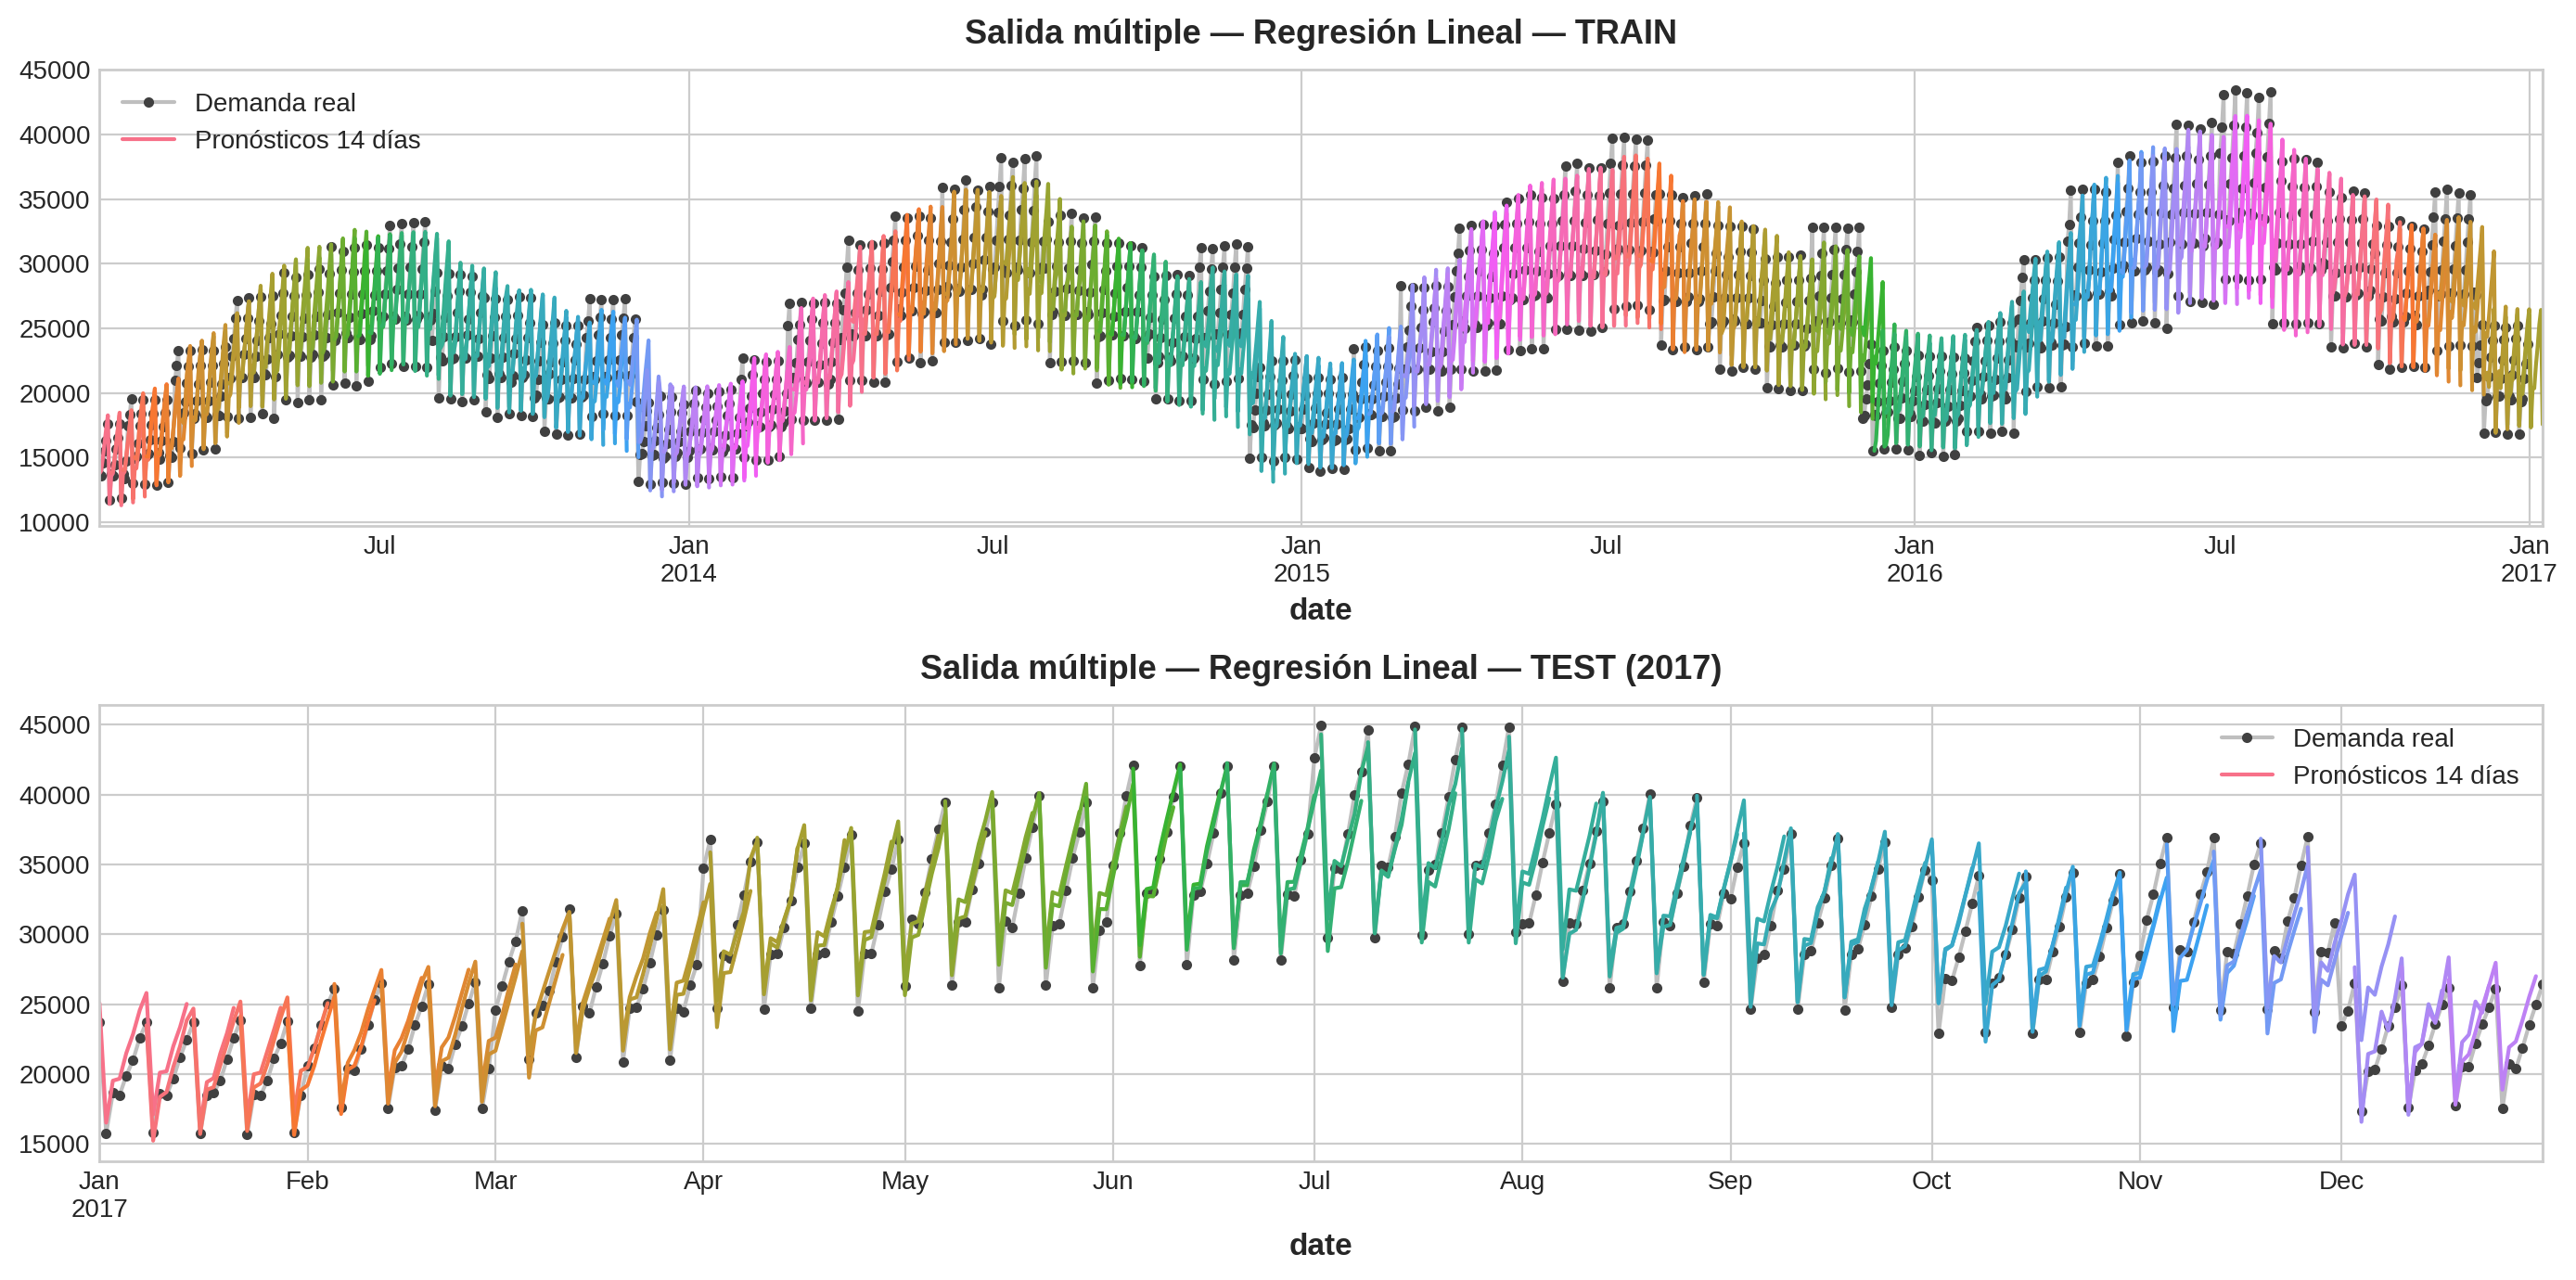

In [ ]:
grafico_train_test(y_fit_mo, y_pred_mo, "Salida múltiple — Regresión Lineal")

**Interpretación:** la regresión lineal de salida múltiple logra un **MAPE de 4.46 % en test**, apenas mejor que el baseline (4.56 %), aunque con un RMSE bastante menor (1 672 vs. 2 307), así que comete menos errores grandes. En el gráfico se ve que el modelo sigue la forma semanal, pero se desfasa en los picos: como es lineal, no puede combinar bien el efecto del día con el nivel de la temporada. Train (4.12 %) y test (4.46 %) son parecidos, así que no hay sobreajuste sino falta de capacidad del modelo (**subajuste**).

## 5.2 Estrategia 2: Directa (Direct) — XGBoost + MultiOutputRegressor

**Explicación técnica:** se entrena **un modelo independiente por cada paso** del horizonte. El modelo 1 aprende a predecir `y_step_1`, el modelo 2 `y_step_2`, …, el modelo 14 `y_step_14`. Todos usan los lags **reales** del día de origen y ninguno ve la predicción de otro.

XGBoost no soporta salidas múltiples en regresión, por eso lo envolvemos con `MultiOutputRegressor`, que entrena un `XGBRegressor` distinto por cada columna de `y_train` (14 modelos).

**XGBoost (boosting):** construye árboles de decisión en secuencia; cada árbol nuevo corrige los errores (residuos) de los anteriores. Así captura relaciones no lineales entre los lags, el día de la semana y la temporada.

- **Ventaja:** cada modelo se especializa en su horizonte y no arrastra errores.
- **Costo:** se entrenan 14 modelos.

In [ ]:
from xgboost import XGBRegressor
from sklearn.multioutput import MultiOutputRegressor

xgb_base = dict(n_estimators=300, learning_rate=0.05, max_depth=4,
                subsample=0.9, colsample_bytree=0.9, random_state=42, n_jobs=-1)

modelo_dir = MultiOutputRegressor(XGBRegressor(**xgb_base))
modelo_dir.fit(X_train, y_train)

y_fit_dir = pd.DataFrame(modelo_dir.predict(X_train), index=X_train.index, columns=y.columns)
y_pred_dir = pd.DataFrame(modelo_dir.predict(X_test), index=X_test.index, columns=y.columns)

print("Modelos entrenados:", len(modelo_dir.estimators_))
print(f"Train MAPE: {metrics.mean_absolute_percentage_error(y_train, y_fit_dir):.2%}")
resultados.append(timeseries_evaluacion_metrica_func(y_test, y_pred_dir, "Directa (XGBoost)"))

Modelos entrenados: 14
Train MAPE: 0.92%
Resultados de la métrica de evaluación — Directa (XGBoost)
  MAE    : 659.173
  RMSE   : 927.321
  MAPE_% : 2.235
  R2     : 0.979


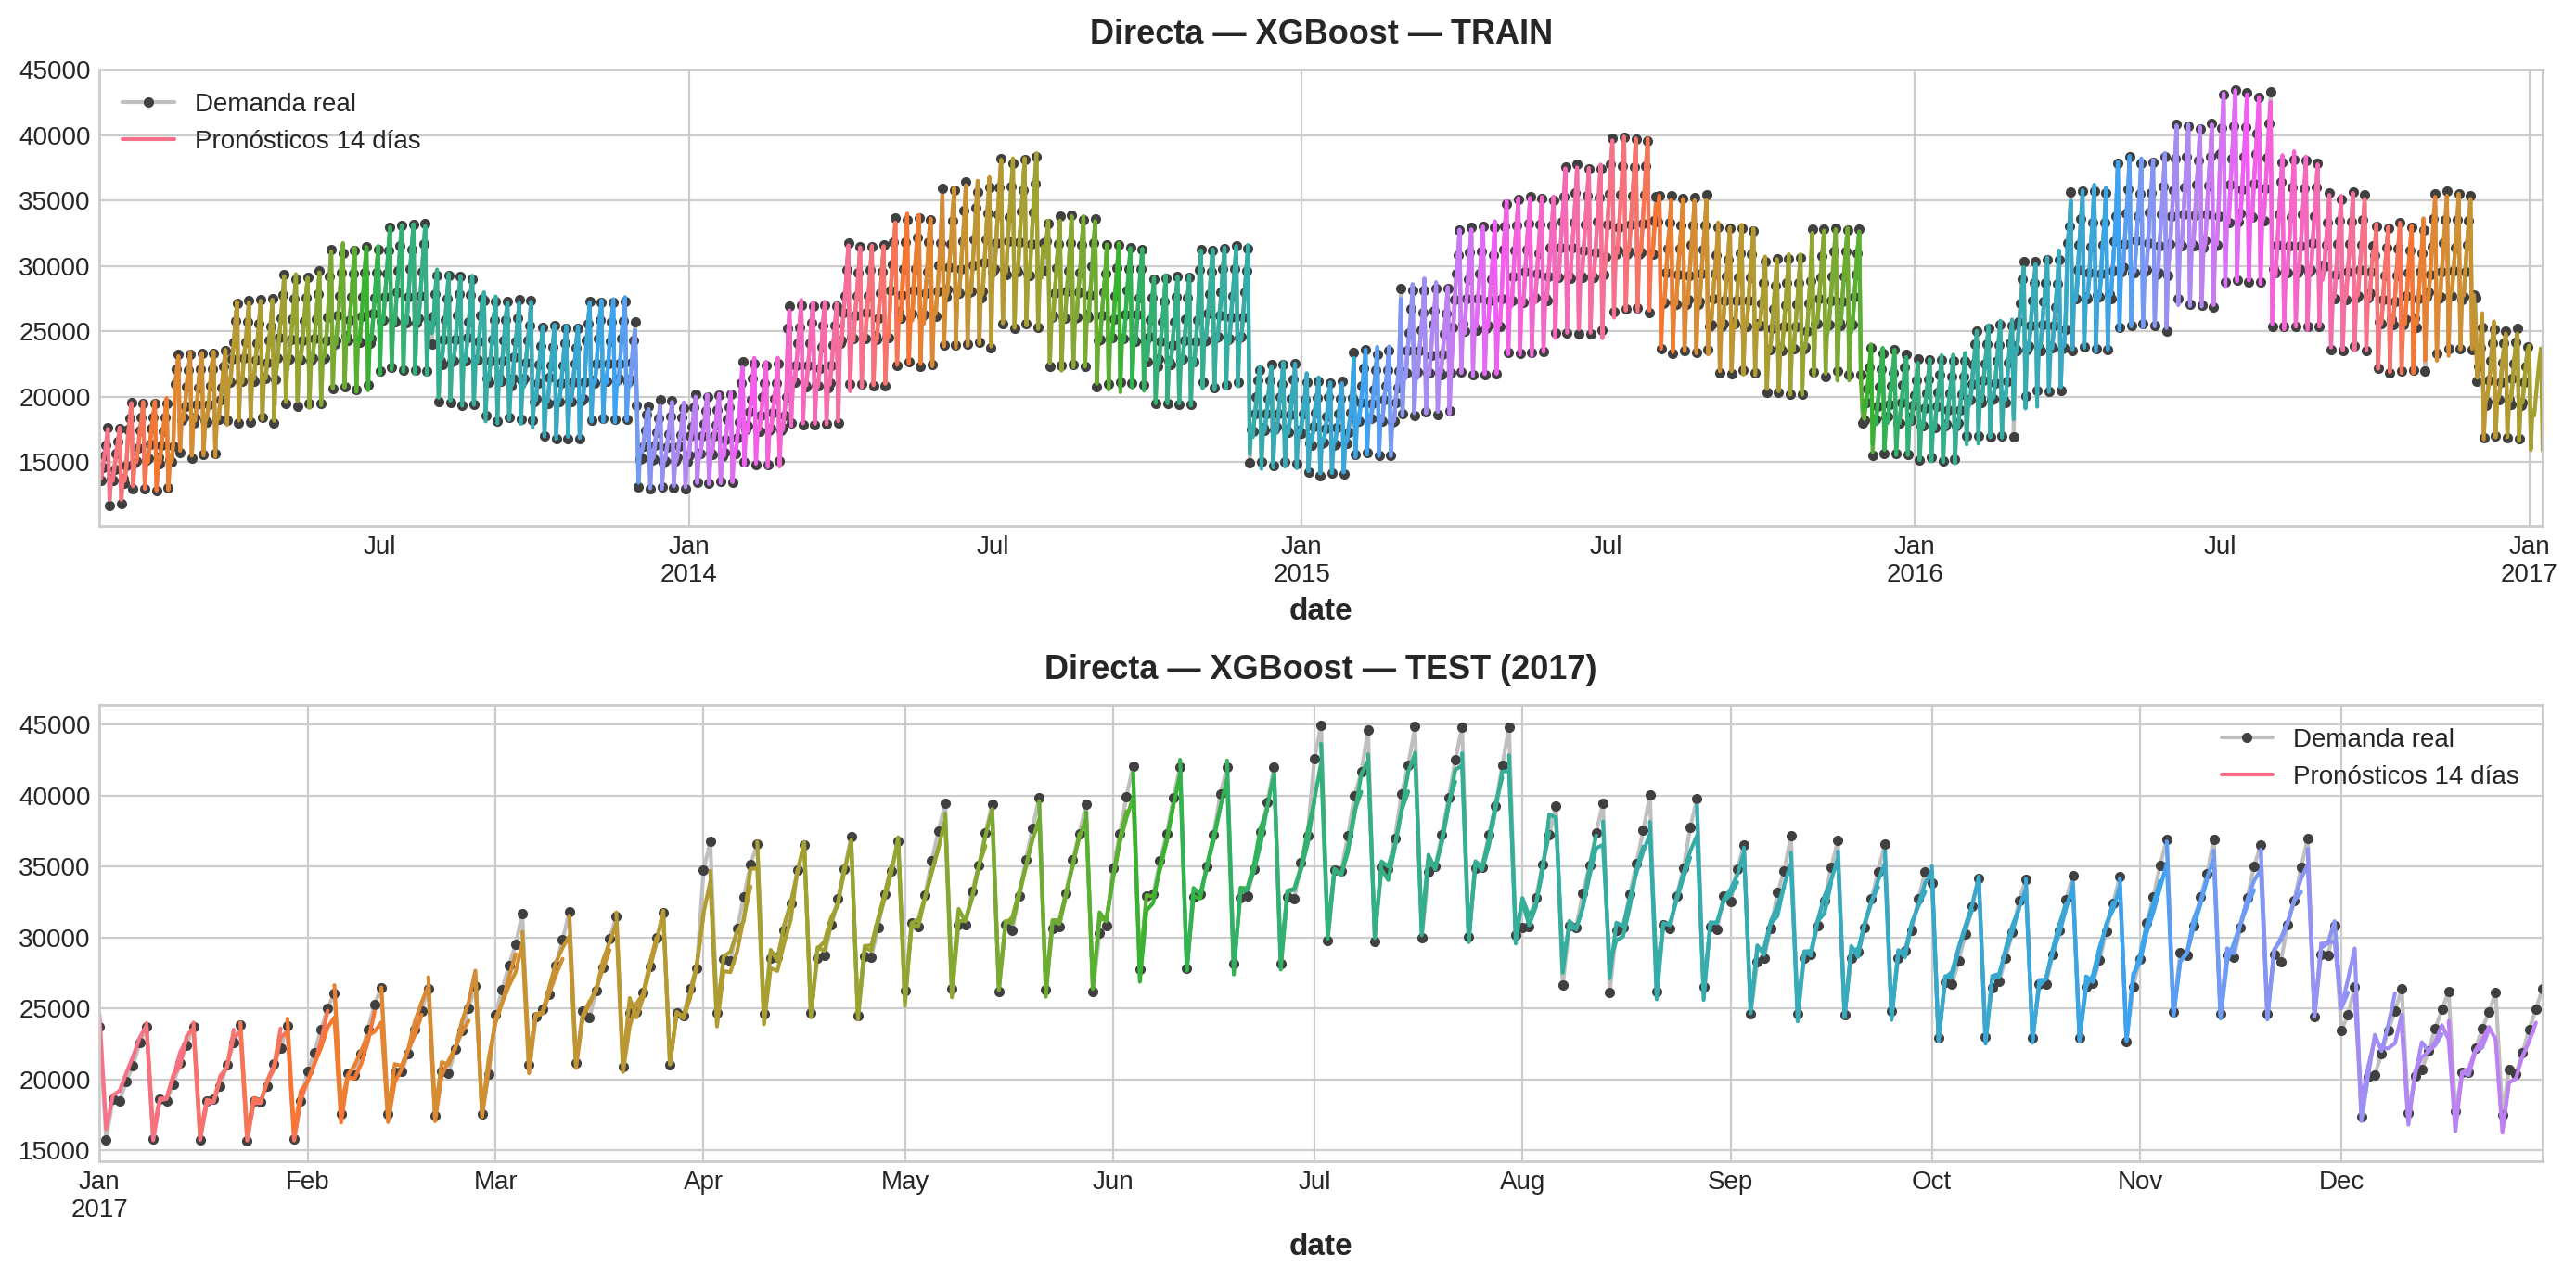

In [ ]:
grafico_train_test(y_fit_dir, y_pred_dir, "Directa — XGBoost")

**Interpretación:** con la estrategia Directa y XGBoost el **MAPE baja a 2.24 %** (casi la mitad que el baseline) y el R² sube a 0.979. En el gráfico de test las líneas de colores (pronósticos de 14 días desde cada origen) casi tapan la demanda real, incluso en el pico de julio y en la caída de diciembre. Hay diferencia entre train (0.92 %) y test (2.24 %), lo que indica algo de sobreajuste, pero el error en test sigue siendo bajo.

## 5.3 Estrategia 3: Recursiva (Recursive) — XGBoost de un paso

**Explicación técnica:** se entrena **un solo modelo** "experto en el mañana" (predice solo 1 día). Para llegar a 14 días, su propia predicción se vuelve el `y_lag_1` del siguiente paso y los demás lags se desplazan (con `np.roll`). Las variables de calendario del día a predecir sí se conocen, así que se actualizan en cada paso.

- **Ventaja:** un solo modelo, fácil de entrenar.
- **Riesgo:** *efecto bola de nieve*: el error del día 1 se usa como dato "real" para el día 2 y se va acumulando.

In [ ]:
# 1) Entrenamos un modelo que SOLO predice el siguiente día (1-step)
modelo_rec = XGBRegressor(**xgb_base)
modelo_rec.fit(X_train, y_train["y_step_1"])

# 2) Bucle recursivo: se aplica a todos los orígenes de test a la vez (vectorizado)
def pronostico_recursivo(modelo, X_origen, horizonte=HORIZONTE):
    lag_cols = [f"y_lag_{i}" for i in range(1, N_LAGS + 1)]
    datos_actuales = X_origen.copy()
    preds = []
    for h in range(horizonte):
        fechas_obj = X_origen.index + pd.Timedelta(days=h)      # día que se predice
        cal = make_calendar(fechas_obj)
        datos_actuales[cal.columns] = cal.values                 # calendario del día objetivo
        pred_manana = modelo.predict(datos_actuales[X.columns])
        preds.append(pred_manana)
        # desplazamos los lags: el lag_1 pasa a ser la predicción que acabamos de hacer
        lags = datos_actuales[lag_cols].values
        lags = np.roll(lags, 1, axis=1)
        lags[:, 0] = pred_manana
        datos_actuales[lag_cols] = lags
    return pd.DataFrame(np.column_stack(preds), index=X_origen.index, columns=y.columns)

y_fit_rec = pronostico_recursivo(modelo_rec, X_train)
y_pred_rec = pronostico_recursivo(modelo_rec, X_test)

print(f"Train MAPE: {metrics.mean_absolute_percentage_error(y_train, y_fit_rec):.2%}")
resultados.append(timeseries_evaluacion_metrica_func(y_test, y_pred_rec, "Recursiva (XGBoost 1-paso)"))

Train MAPE: 1.22%
Resultados de la métrica de evaluación — Recursiva (XGBoost 1-paso)
  MAE    : 724.201
  RMSE   : 1,060.290
  MAPE_% : 2.510
  R2     : 0.973


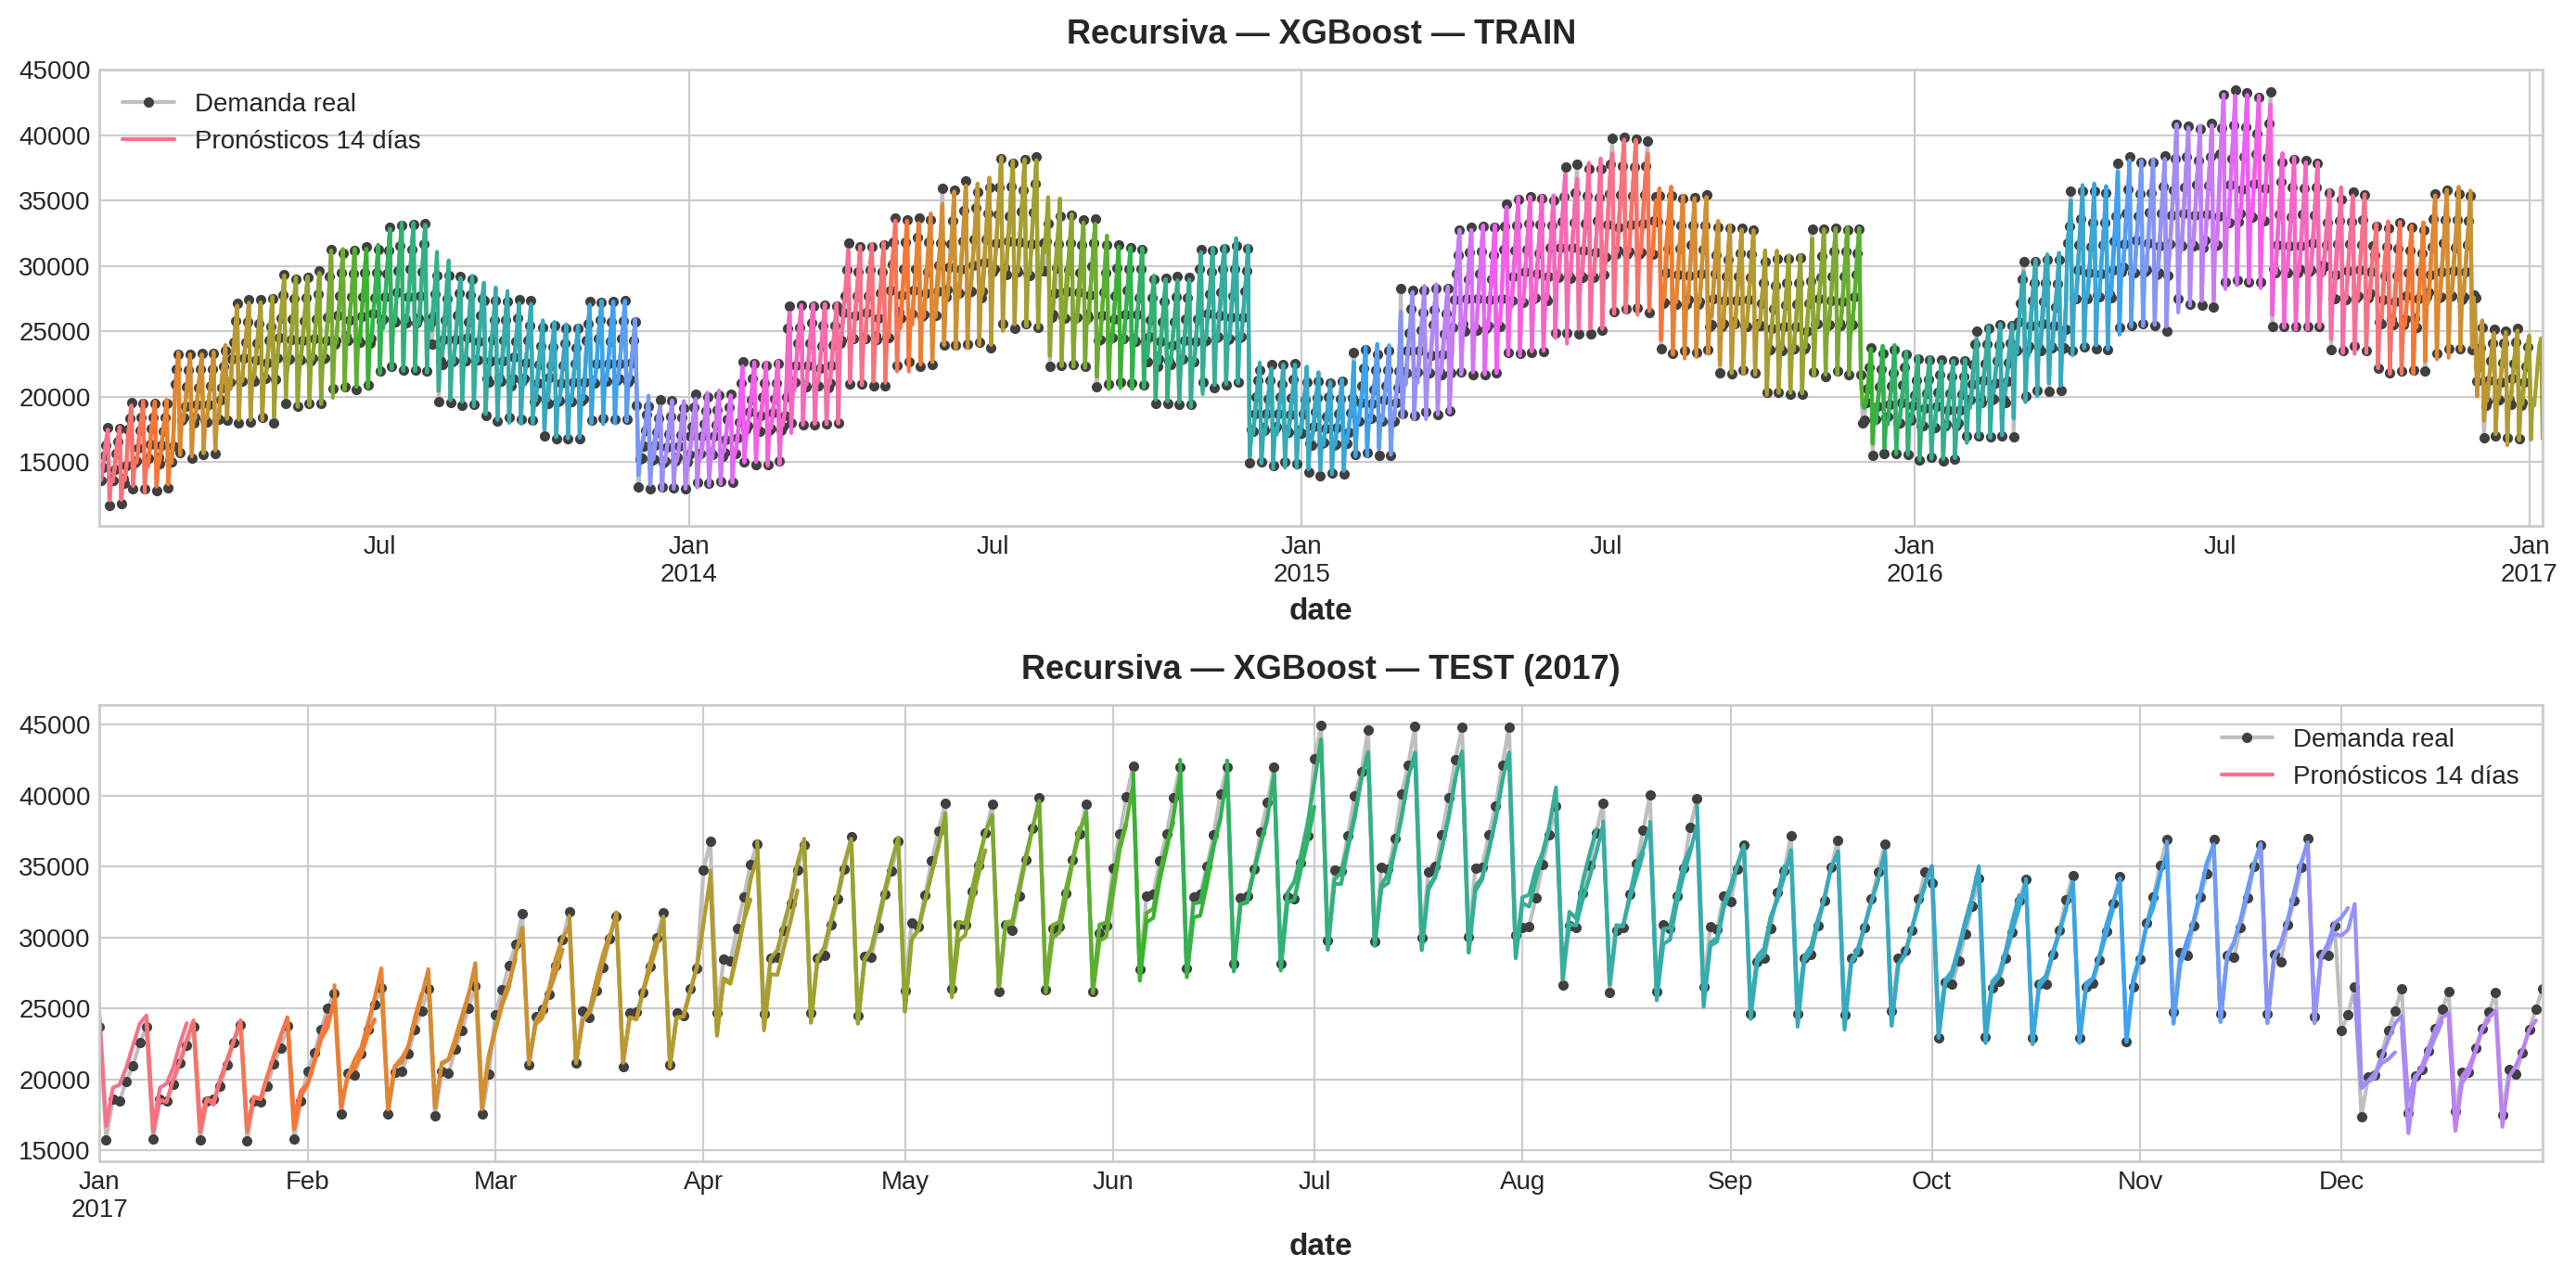

In [ ]:
grafico_train_test(y_fit_rec, y_pred_rec, "Recursiva — XGBoost")

**Interpretación:** la estrategia Recursiva obtiene un **MAPE de 2.51 %**, muy buena pero un poco peor que la Directa. Tiene sentido: como solo hay un modelo que predice "mañana", el error del día 1 entra como lag para el día 2 y así se va acumulando (el *efecto bola de nieve*). Aquí el efecto es moderado porque la serie es muy regular y el horizonte es corto (14 días).

### 5.3.1 Recursiva con la librería `skforecast` (forma simplificada)

`ForecasterRecursive` hace el mismo bucle internamente. Lo entrenamos con la serie hasta el 31/12/2016, con 14 lags y las variables de calendario como **exógenas**, y pronosticamos las **dos primeras semanas de 2017**.

In [ ]:
from skforecast.recursive import ForecasterRecursive

y_serie_train = demanda[demanda.index < corte]
exog_train = make_calendar(y_serie_train.index)
fechas_futuras = pd.date_range(corte, periods=HORIZONTE, freq="D")
exog_futuro = make_calendar(fechas_futuras)

forecaster = ForecasterRecursive(estimator=XGBRegressor(**xgb_base), lags=N_LAGS)
forecaster.fit(y=y_serie_train, exog=exog_train)
pred_skf = forecaster.predict(steps=HORIZONTE, exog=exog_futuro)

comparacion_skf = pd.DataFrame({"real": demanda[fechas_futuras], "pred_skforecast": pred_skf.round(0)})
comparacion_skf["error_%"] = (comparacion_skf["pred_skforecast"] / comparacion_skf["real"] - 1) * 100
display(comparacion_skf)
_ = timeseries_evaluacion_metrica_func(comparacion_skf["real"], comparacion_skf["pred_skforecast"],
                                       "skforecast — 1ra quincena 2017")

,real,pred_skforecast,error_%
2017-01-01,23709,"24,621.00",3.85
2017-01-02,15772,"16,737.00",6.12
2017-01-03,18650,"19,415.00",4.10
2017-01-04,18510,"19,641.00",6.11
2017-01-05,19895,"20,851.00",4.81
2017-01-06,20994,"22,403.00",6.71
2017-01-07,22591,"23,923.00",5.90
2017-01-08,23700,"24,511.00",3.42
2017-01-09,15797,"16,695.00",5.68
2017-01-10,18608,"19,413.00",4.33


Resultados de la métrica de evaluación — skforecast — 1ra quincena 2017
  MAE    : 1,090.357
  RMSE   : 1,117.031
  MAPE_% : 5.486
  R2     : 0.798


**Interpretación:** con `skforecast` obtenemos lo mismo que con el bucle manual, pero en pocas líneas. En esta **única** corrida (desde el 01/01/2017) el modelo sobreestima todos los días entre 3 % y 7 % (MAPE 5.5 %). Es que el arranque de año es la zona más baja y difícil de la serie, y al ser una sola ventana de 14 días el resultado depende mucho del punto de partida. Por eso la evaluación formal la hacemos con los **352 orígenes de 2017** (backtesting) y no con una sola ventana.

## 5.4 Estrategia 4: DirRec (Directa-Recursiva) — XGBoost + RegressorChain

**Explicación técnica:** combina las dos anteriores. Hay **un modelo distinto por cada paso** (como la Directa), pero cada modelo recibe como variable adicional **las predicciones de los pasos anteriores** (como la Recursiva):

- Modelo 1: lags + calendario → predice día 1
- Modelo 2: lags + calendario + pred. día 1 → predice día 2
- Modelo 3: lags + calendario + pred. día 1 y 2 → predice día 3 … y así hasta el día 14.

En código se logra con `RegressorChain`, que encadena un modelo por cada columna de `y` en el orden indicado. Usamos el mismo XGBoost para que la comparación entre estrategias sea justa.

In [ ]:
from sklearn.multioutput import RegressorChain

modelo_dirrec = RegressorChain(XGBRegressor(**xgb_base), order=list(range(HORIZONTE)))
modelo_dirrec.fit(X_train, y_train)

y_fit_dirrec = pd.DataFrame(modelo_dirrec.predict(X_train), index=X_train.index, columns=y.columns)
y_pred_dirrec = pd.DataFrame(modelo_dirrec.predict(X_test), index=X_test.index, columns=y.columns)

print("Modelos en la cadena:", len(modelo_dirrec.estimators_))
print(f"Train MAPE: {metrics.mean_absolute_percentage_error(y_train, y_fit_dirrec):.2%}")
resultados.append(timeseries_evaluacion_metrica_func(y_test, y_pred_dirrec, "DirRec (XGBoost)"))

Modelos en la cadena: 14
Train MAPE: 1.23%
Resultados de la métrica de evaluación — DirRec (XGBoost)
  MAE    : 732.777
  RMSE   : 1,043.138
  MAPE_% : 2.479
  R2     : 0.974


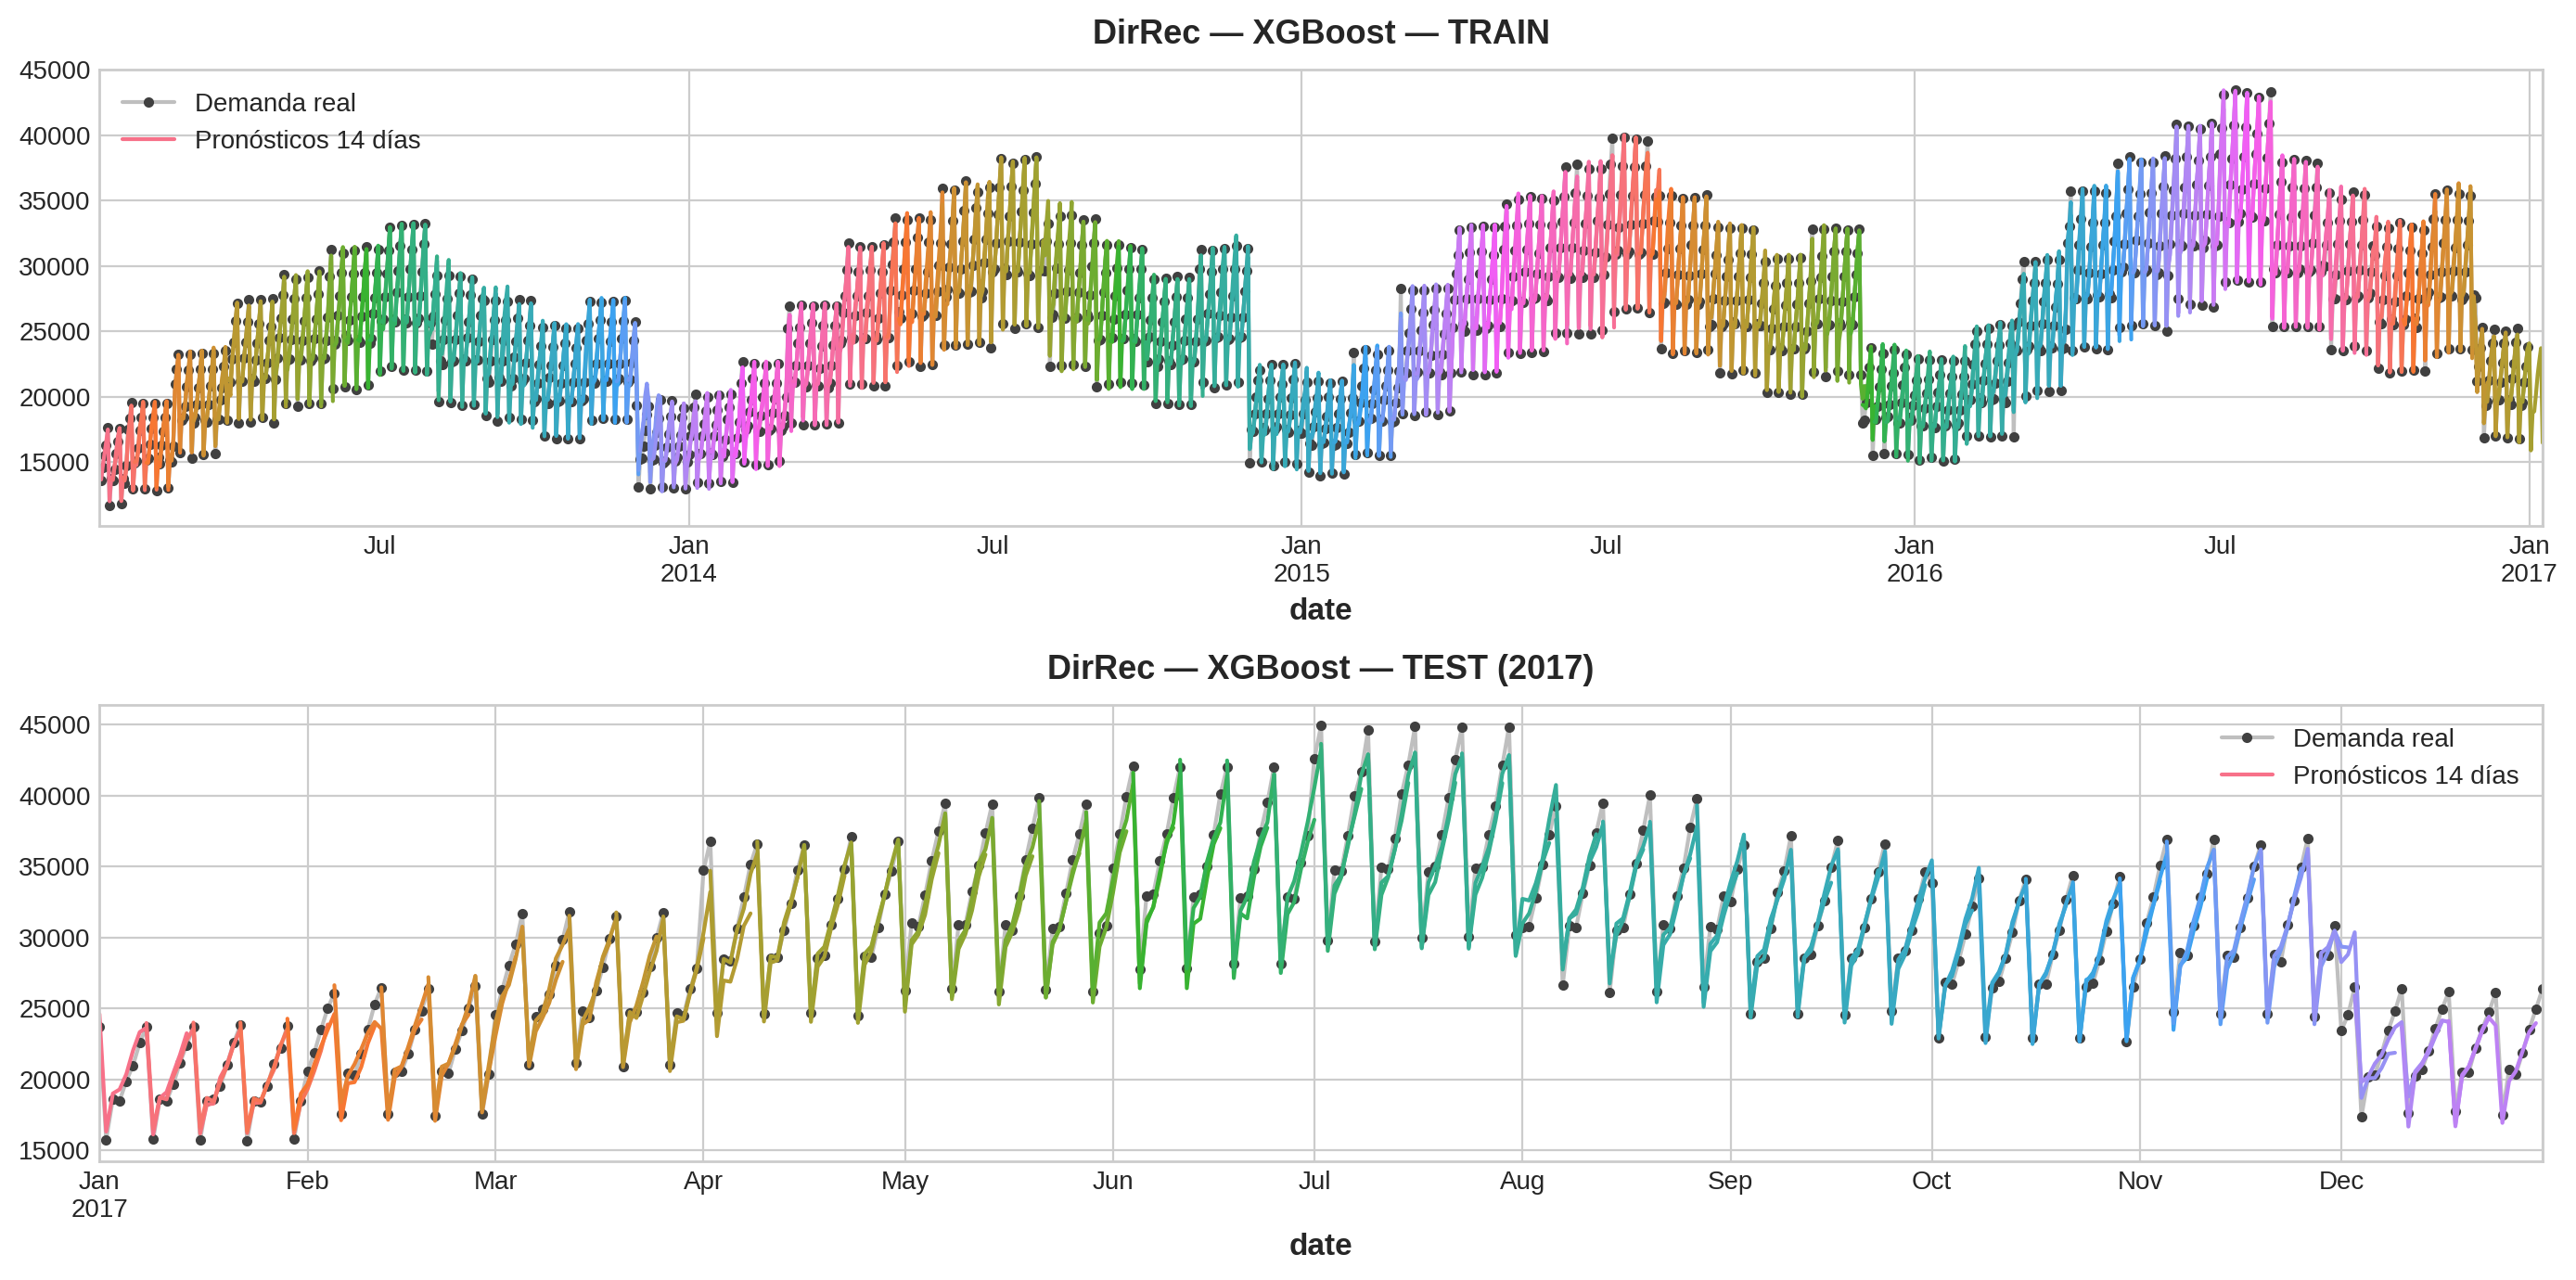

In [ ]:
grafico_train_test(y_fit_dirrec, y_pred_dirrec, "DirRec — XGBoost")

**Interpretación:** DirRec obtiene un **MAPE de 2.48 %**, apenas mejor que la Recursiva (2.51 %) y algo peor que la Directa. Aunque cada modelo recibe las predicciones de los pasos anteriores, esas predicciones traen su propio error y los modelos del final de la cadena terminan apoyándose en ellas. DirRec no siempre gana: depende de los datos.

# 6. Evaluación

## 6.1 ¿Cómo medimos la efectividad de la predicción?

- **Validación temporal (hold-out):** se entrena con 2013–2016 y se evalúa en 2017 completo, que el modelo no vio. Cada día de 2017 es un "origen" desde el cual se pronostican 14 días, así que evaluamos miles de pronósticos (≈352 orígenes × 14 pasos).
- **Métricas:**
  - **MAE:** error promedio en unidades.
  - **RMSE:** como el MAE pero castiga más los errores grandes.
  - **MAPE:** error porcentual promedio (la métrica de negocio).
  - **R²:** qué porcentaje de la variabilidad explica el modelo.
- **Comparación contra baseline:** el modelo solo vale la pena si le gana al método ingenuo.
- **Error por horizonte:** revisar cómo crece el error del día 1 al día 14.

In [ ]:
tabla = (pd.DataFrame(resultados)
           .drop_duplicates(subset="Modelo", keep="last")   # quita repetidos si corriste celdas 2 veces
           .set_index("Modelo")
           .sort_values("MAPE_%"))
mape_base = tabla.loc["Baseline ingenuo (semana anterior)", "MAPE_%"]
tabla["Mejora vs baseline (pts MAPE)"] = mape_base - tabla["MAPE_%"]
tabla.style.format("{:,.3f}").background_gradient(subset=["MAPE_%"], cmap="RdYlGn_r")

,MAE,RMSE,MAPE_%,R2,Mejora vs baseline (pts MAPE)
Modelo,,,,,
Directa (XGBoost),659.173,927.321,2.235,0.979,2.322
DirRec (XGBoost),732.777,"1,043.138",2.479,0.974,2.078
Recursiva (XGBoost 1-paso),724.201,"1,060.290",2.510,0.973,2.047
Salida múltiple (Regresión Lineal),"1,228.320","1,671.972",4.457,0.932,0.100
Baseline ingenuo (semana anterior),"1,270.895","2,306.702",4.557,0.870,0.000


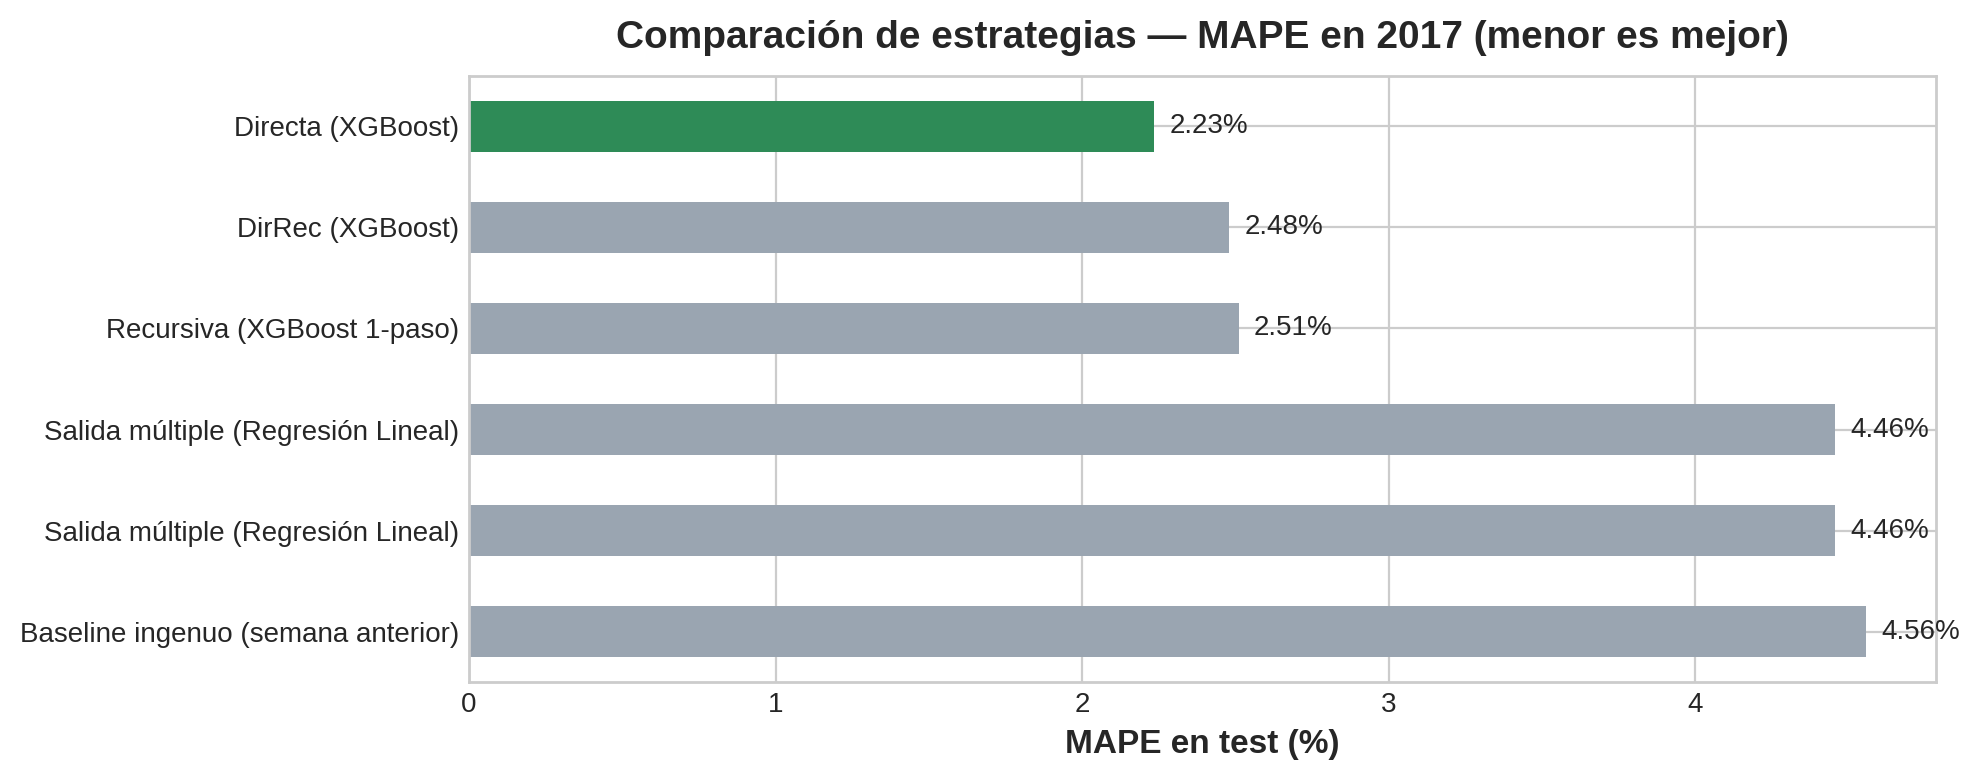

In [ ]:
fig, ax = plt.subplots(figsize=(10, 4))
orden = tabla["MAPE_%"].sort_values()
colores_bar = ["#2E8B57" if i == 0 else "#9aa5b1" for i in range(len(orden))]
orden.plot(kind="barh", ax=ax, color=colores_bar)
for i, v in enumerate(orden.values):
    ax.text(v + 0.05, i, f"{v:.2f}%", va="center")
ax.invert_yaxis(); ax.set_xlabel("MAPE en test (%)"); ax.set_ylabel("")
ax.set_title("Comparación de estrategias — MAPE en 2017 (menor es mejor)");

**Interpretación:** las tres estrategias con XGBoost le ganan claramente al baseline. **La estrategia Directa es la mejor (MAPE 2.24 %, 2.3 puntos menos que el baseline)**, seguida de DirRec (2.48 %) y la Recursiva (2.51 %). La salida múltiple con regresión lineal casi empata con el baseline. La conclusión es que lo que más mejora el pronóstico es el **algoritmo no lineal (XGBoost)**, y entre las estrategias gana la que no arrastra errores de un paso a otro.

## 6.2 Error por horizonte (día 1 al día 14)

Día del horizonte,1,2,3,4,5,6,7,8,9,10,11,12,13,14
Baseline,3.34,3.32,3.30,3.30,3.28,3.27,3.25,5.86,5.85,5.84,5.83,5.81,5.79,5.78
Salida múltiple (LR),2.06,2.67,3.18,3.57,3.95,4.21,4.36,4.92,5.18,5.38,5.61,5.71,5.78,5.82
Directa (XGB),2.04,1.96,2.08,1.99,1.99,2.04,2.23,2.47,2.28,2.42,2.40,2.55,2.36,2.47
Recursiva (XGB),2.04,2.30,2.42,2.41,2.42,2.41,2.40,2.59,2.71,2.69,2.69,2.68,2.68,2.70
DirRec (XGB),2.04,2.20,2.22,2.16,2.21,2.19,2.36,2.46,2.59,2.93,2.69,2.79,2.75,3.11


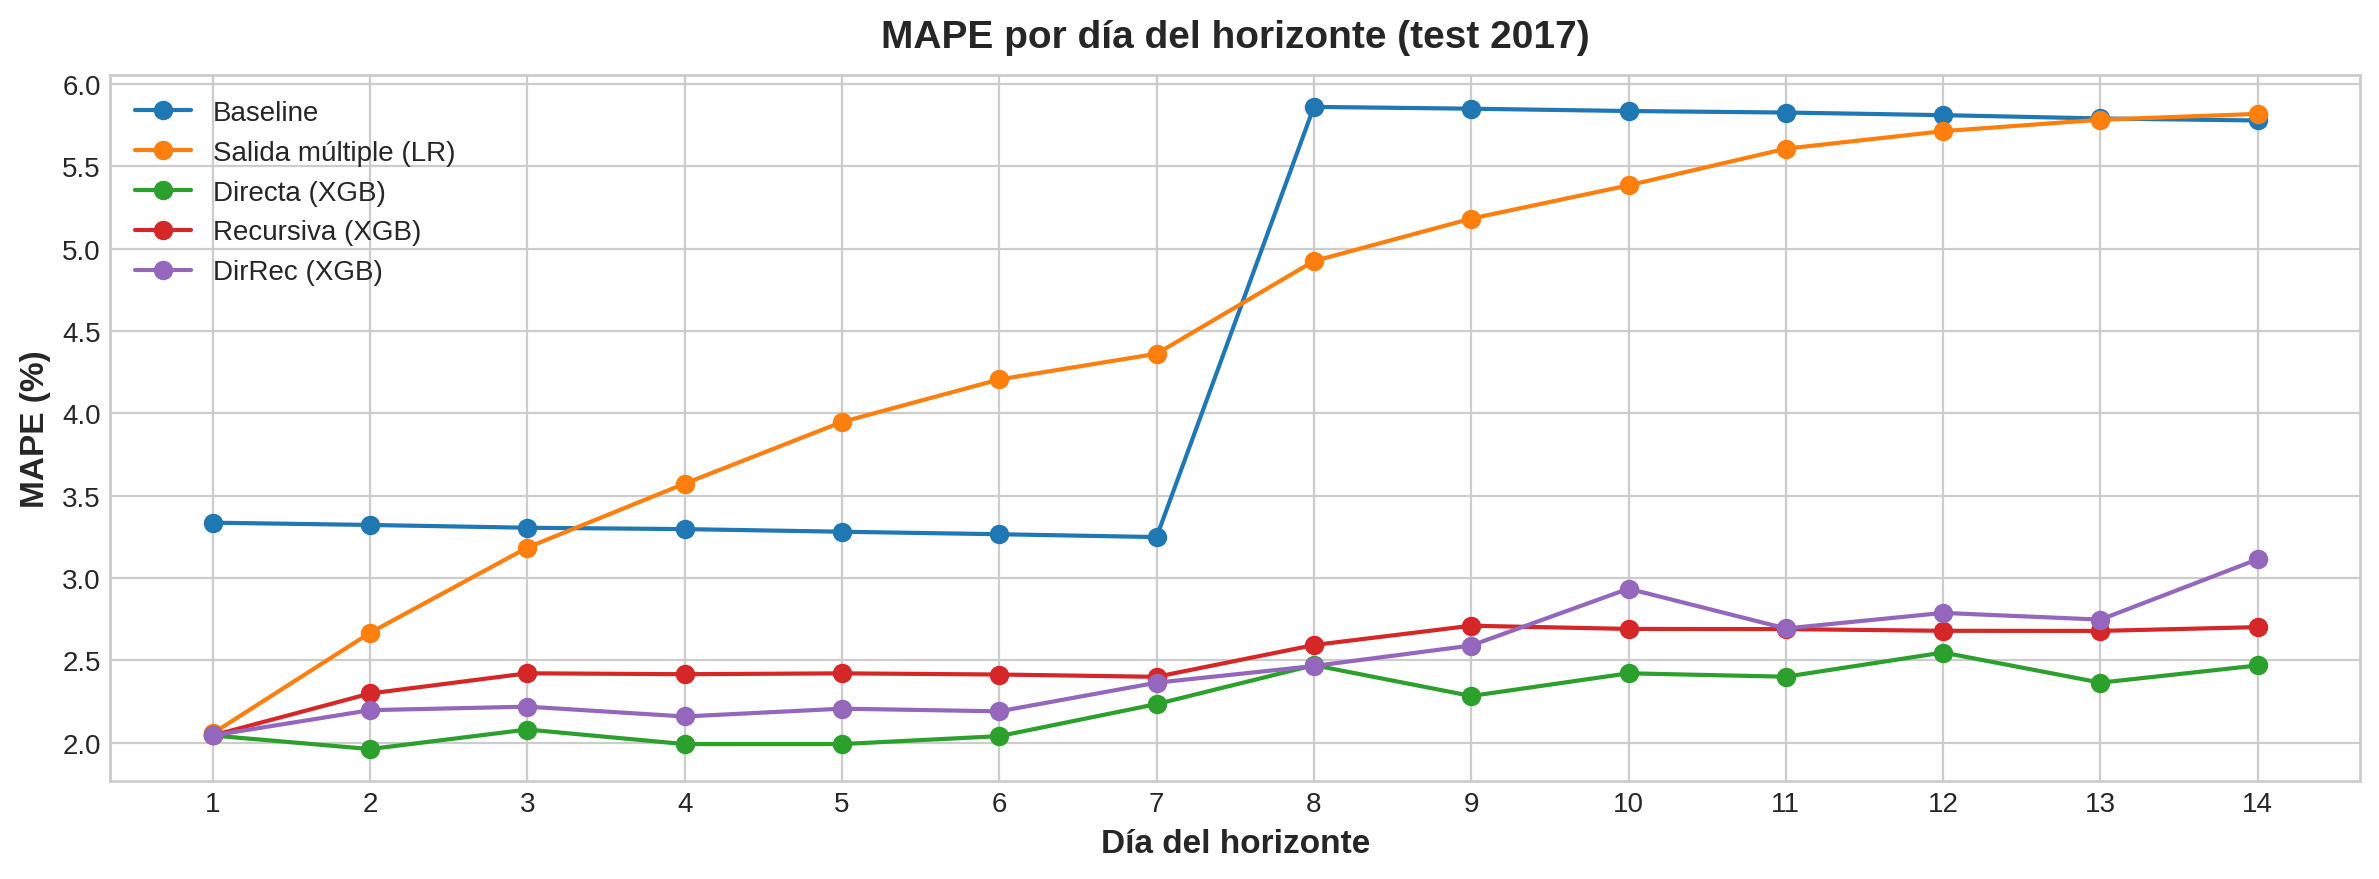

In [ ]:
preds_test = {"Baseline": y_pred_naive, "Salida múltiple (LR)": y_pred_mo, "Directa (XGB)": y_pred_dir,
              "Recursiva (XGB)": y_pred_rec, "DirRec (XGB)": y_pred_dirrec}

mape_h = pd.DataFrame({
    nombre: [metrics.mean_absolute_percentage_error(y_test.iloc[:, h], p.iloc[:, h]) * 100
             for h in range(HORIZONTE)]
    for nombre, p in preds_test.items()}, index=range(1, HORIZONTE + 1))
mape_h.index.name = "Día del horizonte"

ax = mape_h.plot(marker="o", figsize=(12, 4.5), title="MAPE por día del horizonte (test 2017)")
ax.set_ylabel("MAPE (%)"); ax.set_xticks(range(1, 15));
mape_h.round(2).T

**Interpretación:**
- El **baseline** tiene error constante en los días 1–7 (3.3 %) y salta a 5.8 % en los días 8–14, porque ahí ya repite una semana que también es "copiada".
- La **Regresión Lineal** empeora de forma sostenida del día 1 (2.1 %) al día 14 (5.8 %).
- **Recursiva y DirRec** empiezan igual que la Directa (2.04 % en el día 1, porque en ese paso los tres usan lags reales) y luego suben de a pocos hasta 2.7–3.1 %: es la acumulación de error.
- **La Directa se mantiene estable** entre 2.0 % y 2.6 % en los 14 días. Es la más confiable para planificar a dos semanas.

## 6.3 Ajuste de hiperparámetros del mejor modelo (RandomizedSearchCV)

Probamos combinaciones aleatorias de hiperparámetros con distribuciones. Para no "hacer trampa" con el tiempo usamos `TimeSeriesSplit` (cada fold valida siempre sobre fechas posteriores a las de entrenamiento) y solo con los datos de train.

In [ ]:
import scipy.stats as stats
from sklearn.model_selection import RandomizedSearchCV, TimeSeriesSplit

distribuciones = {
    "estimator__n_estimators": stats.randint(200, 700),
    "estimator__max_depth": stats.randint(3, 7),
    "estimator__learning_rate": stats.uniform(0.02, 0.08),
    "estimator__subsample": stats.uniform(0.7, 0.3),
}

busqueda = RandomizedSearchCV(
    MultiOutputRegressor(XGBRegressor(random_state=42, n_jobs=-1, colsample_bytree=0.9)),
    distribuciones, n_iter=8, cv=TimeSeriesSplit(n_splits=3),
    scoring="neg_mean_absolute_percentage_error", random_state=12345, n_jobs=1)
busqueda.fit(X_train, y_train)

print("Mejores hiperparámetros:", {k.replace("estimator__", ""): (round(float(v), 3) if isinstance(v, float) else int(v))
                                  for k, v in busqueda.best_params_.items()})
print(f"MAPE promedio en validación cruzada temporal: {-busqueda.best_score_:.2%}")

y_pred_tuned = pd.DataFrame(busqueda.predict(X_test), index=X_test.index, columns=y.columns)
res_tuned = timeseries_evaluacion_metrica_func(y_test, y_pred_tuned, "Directa (XGBoost ajustado)")

Mejores hiperparámetros: {'learning_rate': 0.097, 'max_depth': 4, 'n_estimators': 547, 'subsample': 0.893}
MAPE promedio en validación cruzada temporal: 3.83%
Resultados de la métrica de evaluación — Directa (XGBoost ajustado)
  MAE    : 665.160
  RMSE   : 931.736
  MAPE_% : 2.252
  R2     : 0.979


**Interpretación:** la búsqueda aleatoria eligió ≈547 árboles, profundidad 4, *learning rate* ≈0.097 y *subsample* ≈0.89. Sin embargo, en test el modelo ajustado obtiene un **MAPE de 2.25 %**, prácticamente igual al de la configuración inicial (2.24 %), así que el ajuste no aporta mejora y **se mantiene la configuración inicial** (el código lo decide automáticamente en las celdas siguientes). El MAPE de validación cruzada (3.83 %) sale más alto porque en los primeros folds el modelo entrena con muy poca historia (menos de un año) y no llega a ver una temporada completa.

## 6.4 Real vs. pronóstico en test e importancia de variables

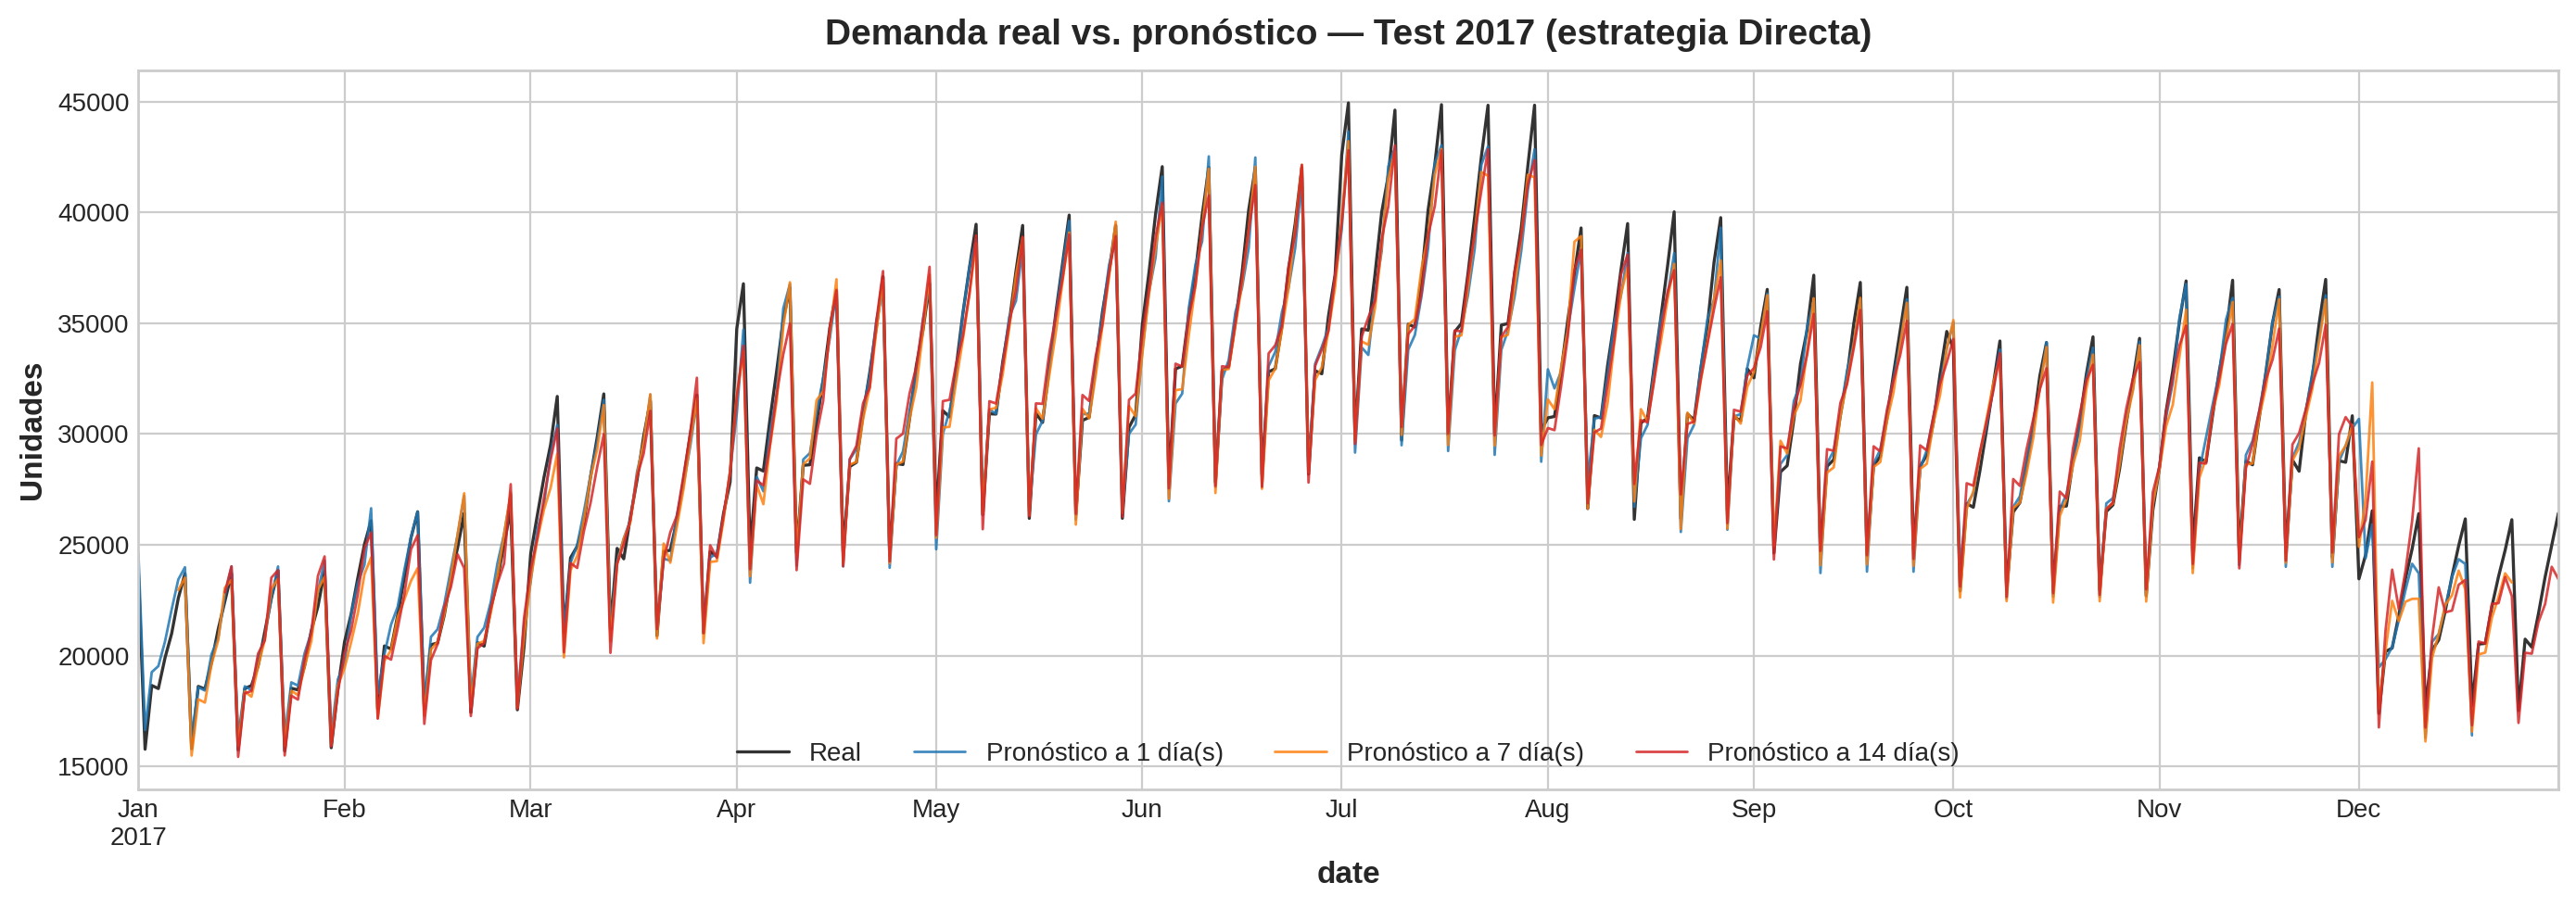

In [ ]:
# Pronóstico a 1, 7 y 14 días del mejor modelo, alineado a la fecha objetivo
mejor_pred = y_pred_tuned if res_tuned["MAPE_%"] < tabla["MAPE_%"].min() else y_pred_dir
fig, ax = plt.subplots(figsize=(14, 5))
demanda["2017"].plot(ax=ax, color="0.2", lw=1.2, label="Real")
for h, c in zip([1, 7, 14], ["C0", "C1", "C3"]):
    serie = mejor_pred[f"y_step_{h}"].copy()
    serie.index = serie.index + pd.Timedelta(days=h - 1)
    serie.plot(ax=ax, color=c, lw=1, alpha=0.85, label=f"Pronóstico a {h} día(s)")
ax.set_title("Demanda real vs. pronóstico — Test 2017 (estrategia Directa)")
ax.set_ylabel("Unidades"); ax.legend(ncol=4);

**Interpretación:** se compara la demanda real de 2017 (negro) con lo que el modelo pronosticó con 1, 7 y 14 días de anticipación. Las tres curvas siguen muy de cerca a la real, incluso con 14 días de anticipación. Los desvíos más visibles aparecen **en los cambios de mes** (inicio de abril y sobre todo inicio de diciembre), que es cuando la demanda cambia de nivel de golpe, y en algunos picos de domingo de julio.

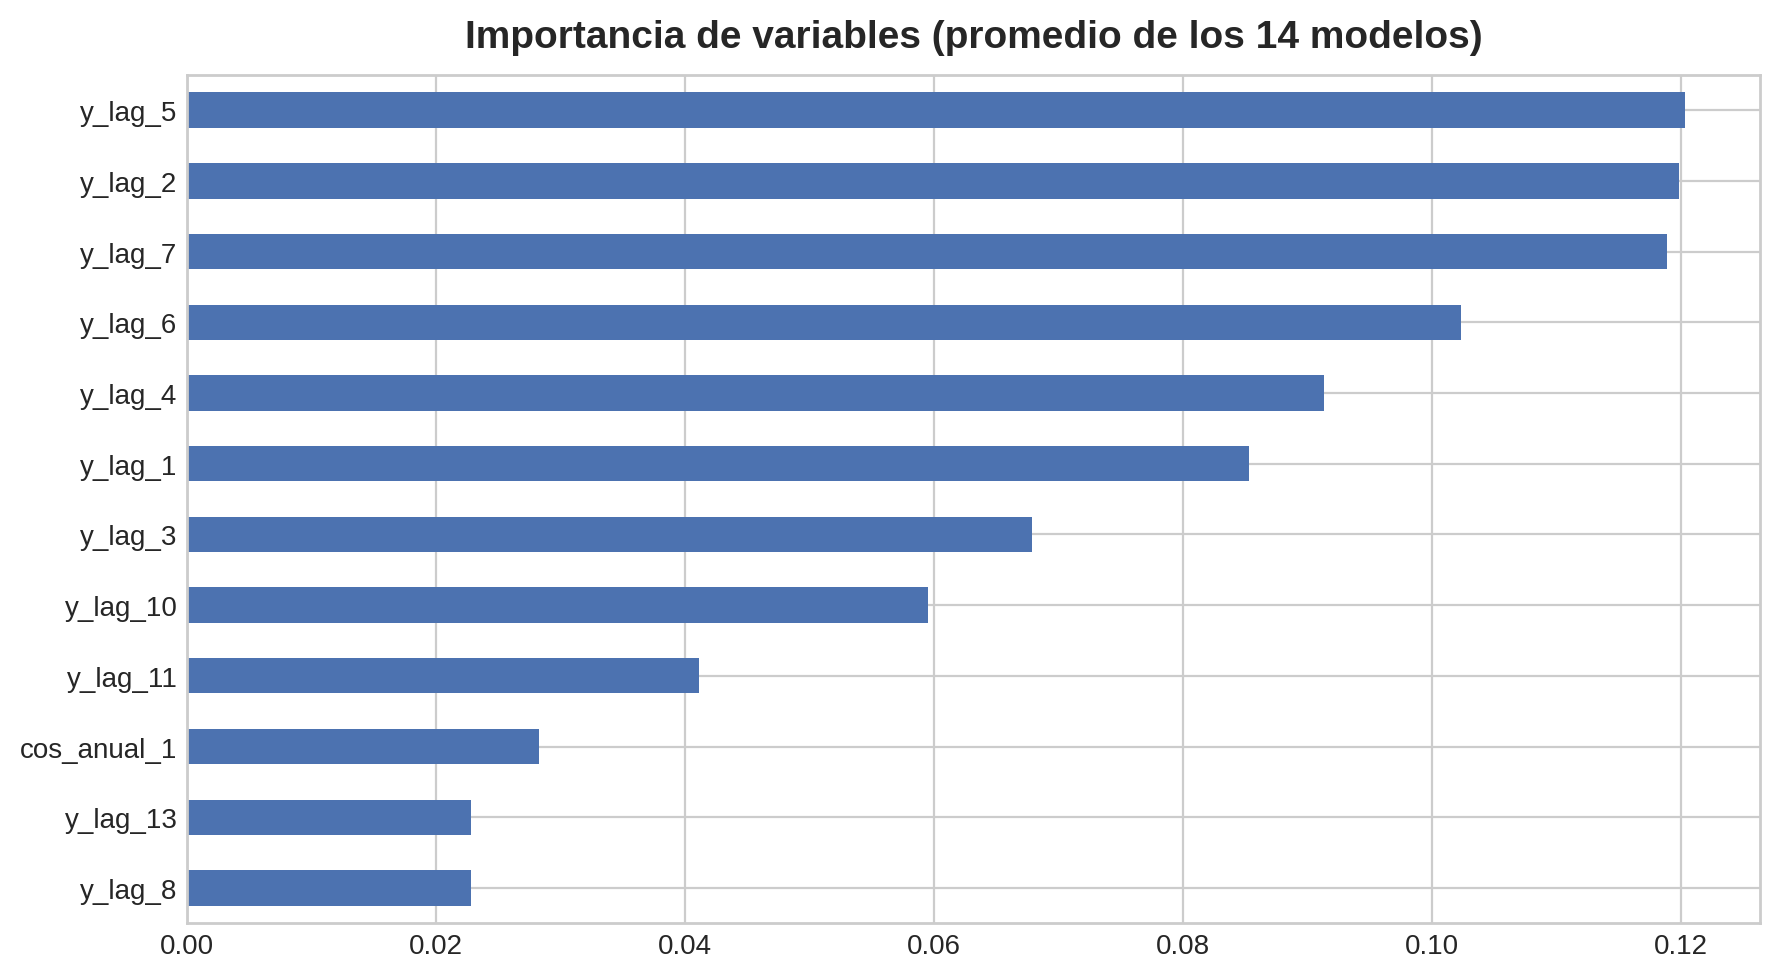

,h1,h7,h14,promedio_14_modelos
y_lag_5,0.00,0.00,0.00,0.12
y_lag_2,0.01,0.14,0.05,0.12
y_lag_7,0.83,0.00,0.01,0.12
y_lag_6,0.00,0.00,0.00,0.10
y_lag_4,0.00,0.00,0.00,0.09
y_lag_1,0.05,0.49,0.52,0.09
y_lag_3,0.00,0.01,0.00,0.07
y_lag_10,0.00,0.00,0.00,0.06
y_lag_11,0.00,0.00,0.00,0.04
cos_anual_1,0.01,0.02,0.04,0.03


In [ ]:
mejor_estimadores = (busqueda.best_estimator_ if res_tuned["MAPE_%"] < tabla["MAPE_%"].min() else modelo_dir).estimators_
importancias = pd.DataFrame({f"h{h+1}": est.feature_importances_ for h, est in enumerate(mejor_estimadores)},
                            index=X.columns)
fi = importancias[["h1", "h7", "h14"]].copy()
fi["promedio_14_modelos"] = importancias.mean(axis=1)
fi = fi.sort_values("promedio_14_modelos", ascending=False)

fi["promedio_14_modelos"].head(12).sort_values().plot(kind="barh", figsize=(9, 5), color="#4C72B0",
    title="Importancia de variables (promedio de los 14 modelos)")
plt.show()
fi.head(10).round(3)

**Interpretación:** en los modelos la información más valiosa es **la demanda del mismo día de la semana anterior**:
- Para el **día 1 (h1)** la variable principal es `y_lag_7` (83 %): para predecir el día *t* mira el día *t−7*.
- Para los **días 7 y 14 (h7, h14)** la principal es `y_lag_1`, porque el día *t−1* cae justamente en el mismo día de la semana que *t+6* y *t+13*.

Después vienen los otros lags y `cos_anual_1` (la estacionalidad anual). Esto coincide con lo que se vio en el EDA (lag 7 con r = 0.97).

# 7. Pronóstico final: próximos 14 días (01/01/2018 – 14/01/2018)

Con la estrategia elegida, se **reentrena con todos los datos** (2013–2017) y se pronostica desde el último dato real disponible, que es justamente lo que se haría en producción.

In [ ]:
params_finales = {k.replace("estimator__", ""): v for k, v in busqueda.best_params_.items()} \
    if res_tuned["MAPE_%"] < tabla["MAPE_%"].min() else {k: v for k, v in xgb_base.items() if k not in ("colsample_bytree", "random_state", "n_jobs")}
modelo_final = MultiOutputRegressor(XGBRegressor(random_state=42, n_jobs=-1, colsample_bytree=0.9, **params_finales))
modelo_final.fit(X, y)

# Fila de origen: 2018-01-01 (lags = últimos 14 días reales, calendario del 1 de enero)
origen = pd.Timestamp("2018-01-01")
historia = demanda.iloc[-N_LAGS:][::-1].values          # y_lag_1 = 31/12/2017, ..., y_lag_14
x_origen = pd.DataFrame([historia], columns=[f"y_lag_{i}" for i in range(1, N_LAGS + 1)], index=[origen])
x_origen = x_origen.join(make_calendar(pd.DatetimeIndex([origen])))[X.columns]

pronostico = pd.Series(modelo_final.predict(x_origen)[0],
                       index=pd.date_range(origen, periods=HORIZONTE, freq="D"), name="pronostico")
tabla_pron = pronostico.round(0).astype(int).to_frame()
tabla_pron["dia"] = [dias[d] for d in tabla_pron.index.dayofweek]
display(tabla_pron.T)
print(f"Demanda total pronosticada para las 2 semanas: {pronostico.sum():,.0f} unidades")

,2018-01-01,2018-01-02,2018-01-03,2018-01-04,2018-01-05,2018-01-06,2018-01-07,2018-01-08,2018-01-09,2018-01-10,2018-01-11,2018-01-12,2018-01-13,2018-01-14
pronostico,17011,20276,20015,21443,22825,23809,25735,16841,19647,19642,21479,22788,24411,24655
dia,Lun,Mar,Mié,Jue,Vie,Sáb,Dom,Lun,Mar,Mié,Jue,Vie,Sáb,Dom


Demanda total pronosticada para las 2 semanas: 300,578 unidades


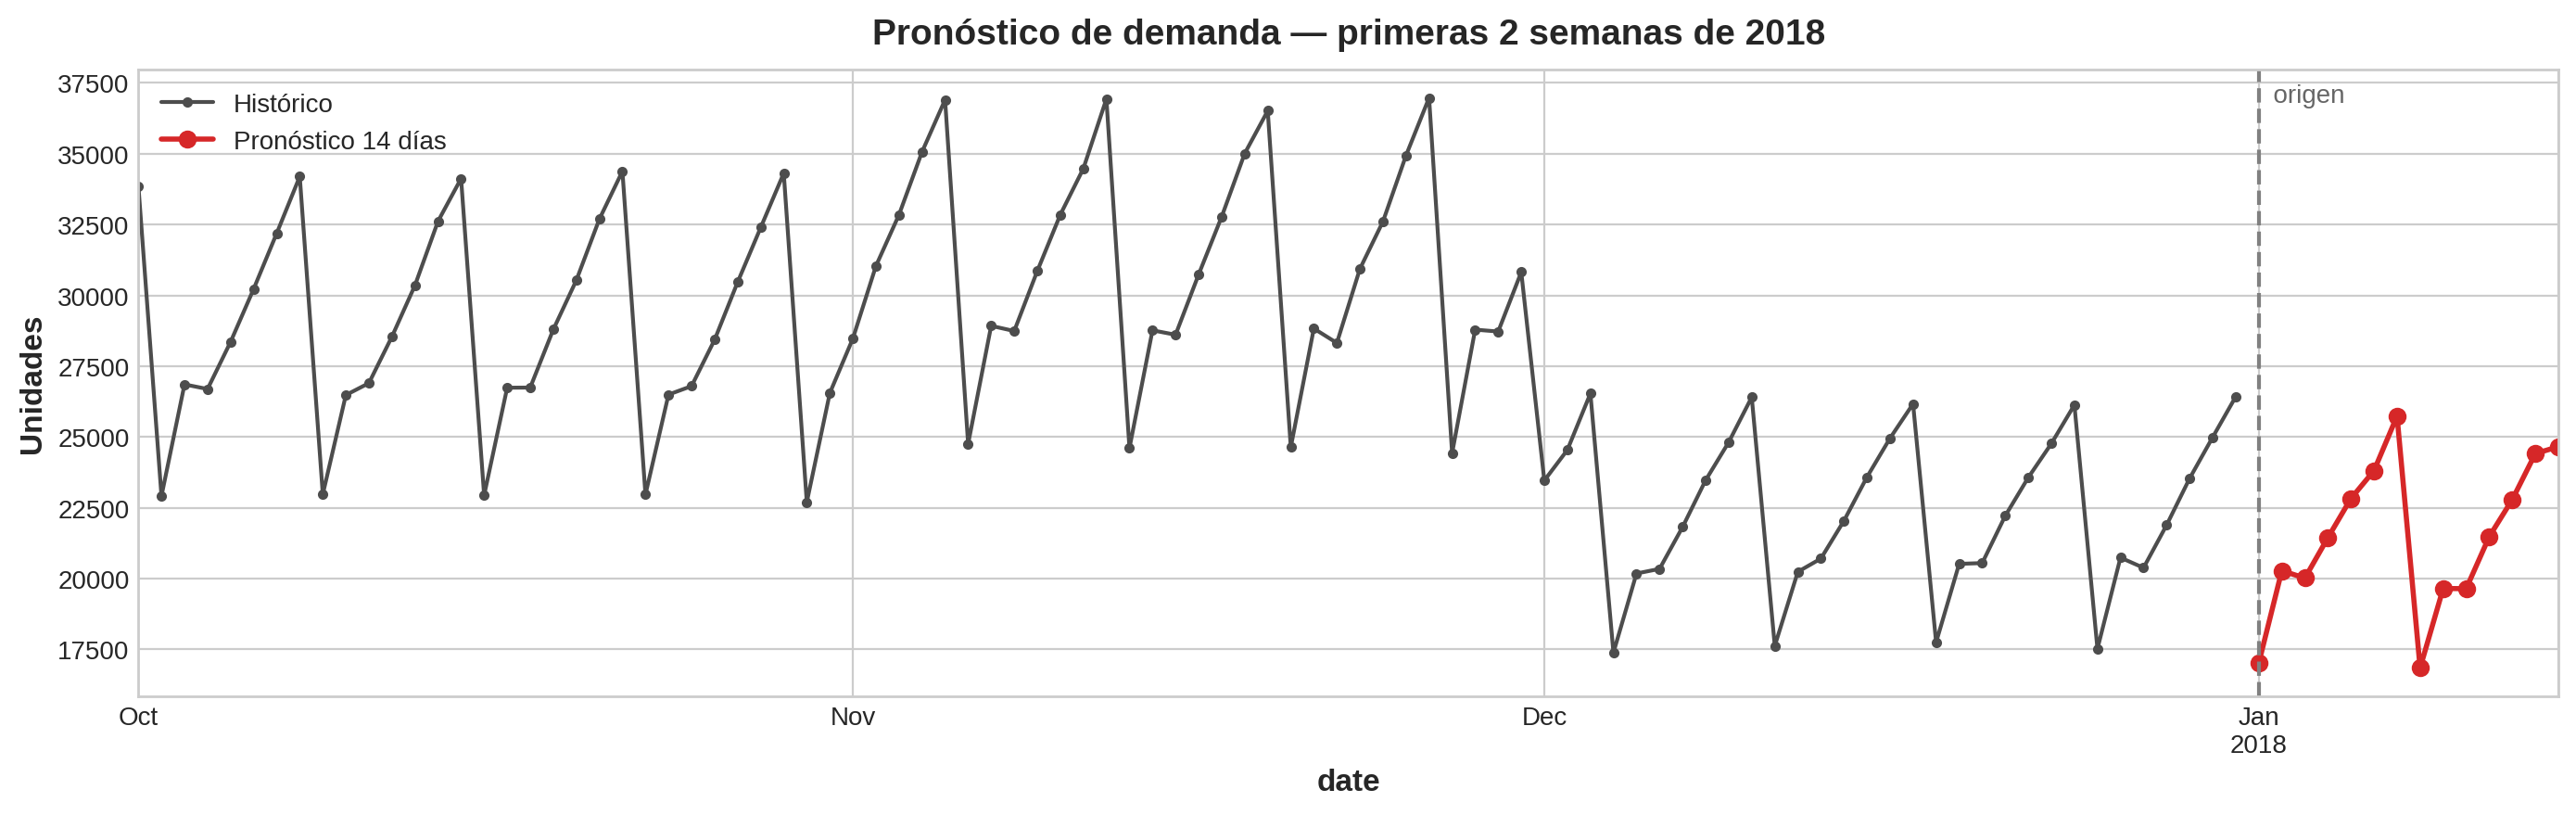

In [ ]:
fig, ax = plt.subplots(figsize=(14, 4.5))
demanda["2017-10-01":].plot(ax=ax, color="0.3", marker=".", label="Histórico")
pronostico.plot(ax=ax, color="C3", marker="o", lw=2, label="Pronóstico 14 días")
ax.axvline(origen, color="0.5", ls="--"); ax.text(origen, ax.get_ylim()[1]*0.97, "  origen", color="0.4")
ax.set_title("Pronóstico de demanda — primeras 2 semanas de 2018"); ax.set_ylabel("Unidades"); ax.legend();

**Interpretación:** el modelo final (Directa + XGBoost, reentrenado con los 5 años) pronostica **≈301 mil unidades para las dos primeras semanas de 2018**. Se respeta el patrón semanal (lunes bajo ≈17 mil, domingo alto ≈25 mil) y el nivel es coherente con enero, que es temporada baja. La segunda semana sale un poco más alta que la primera, igual que en años anteriores después de Año Nuevo. Esta es la tabla que usaría el área de compras para programar pedidos.

# 8. Propuesta de despliegue

¿Cómo llevaríamos este modelo a un entorno de producción? La propuesta es un **pipeline batch diario**, porque el negocio necesita el pronóstico una vez al día (antes de generar las órdenes de reposición), no en tiempo real.

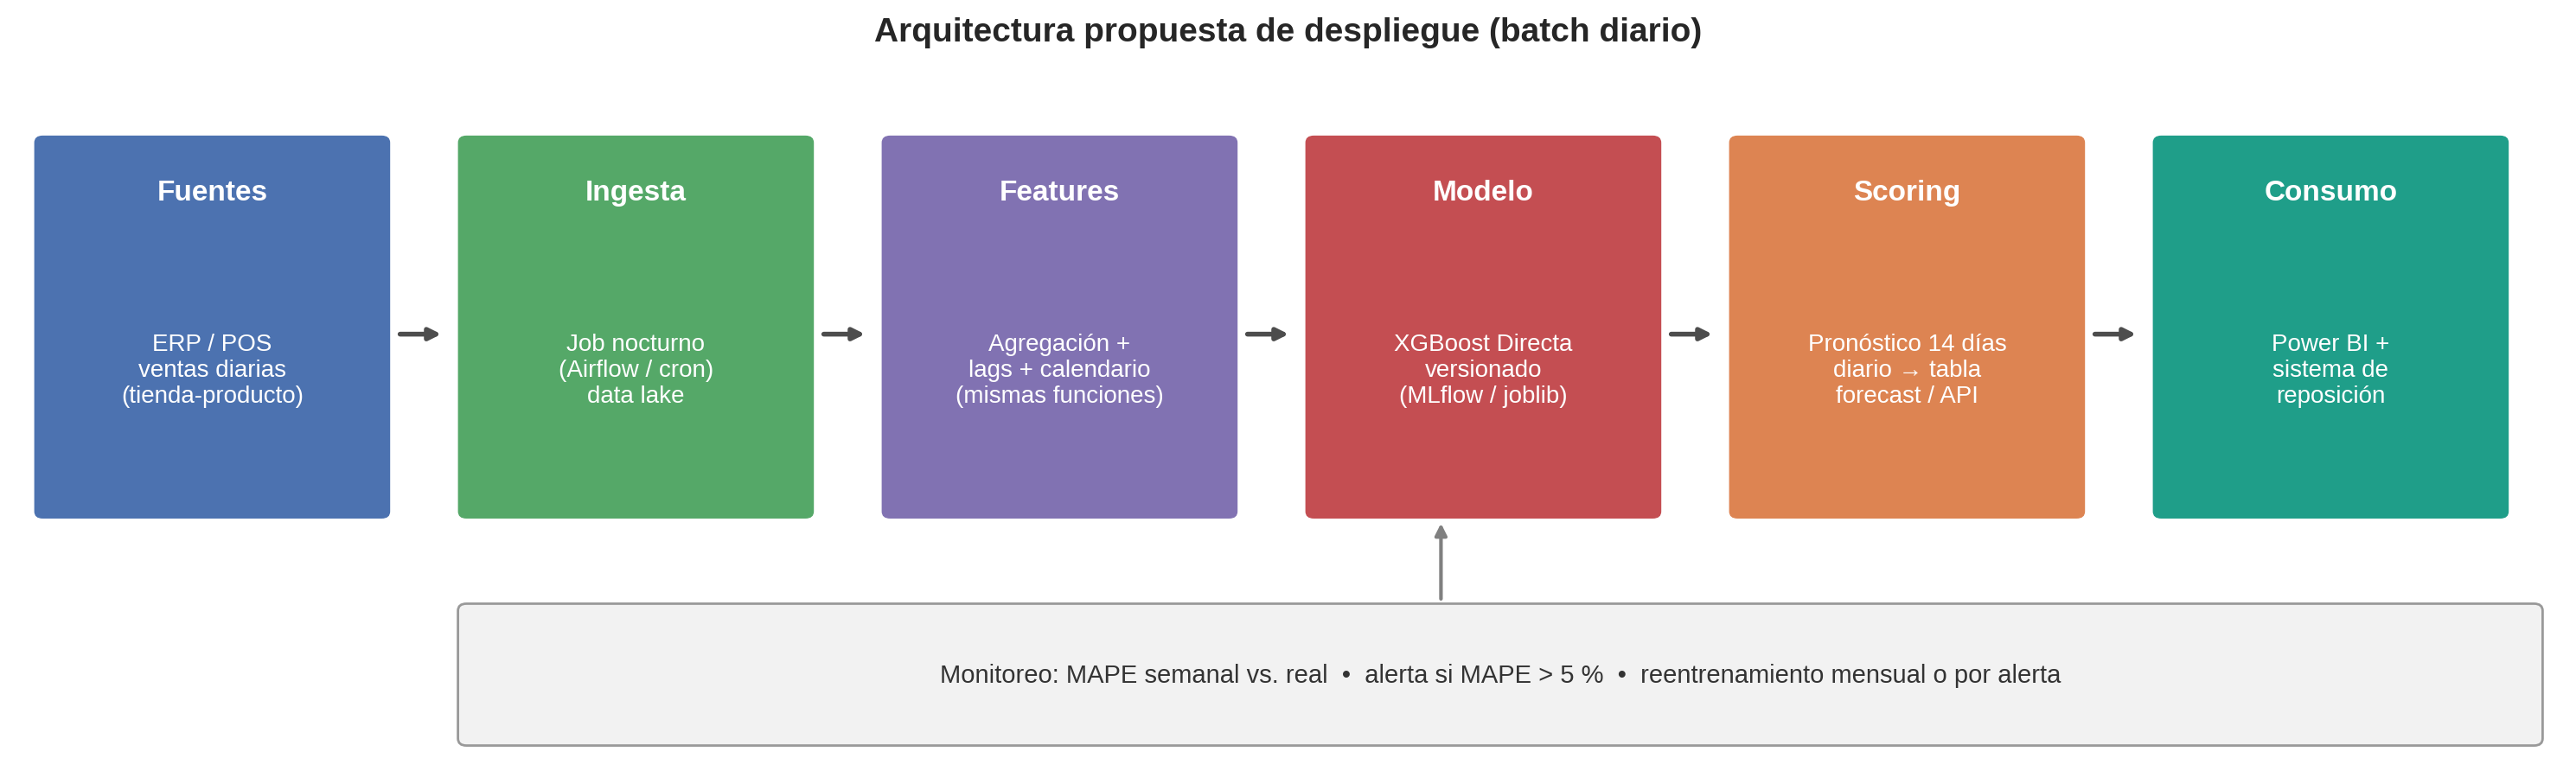

In [ ]:
capas = [
    ("Fuentes", "ERP / POS\nventas diarias\n(tienda-producto)", "#4C72B0"),
    ("Ingesta", "Job nocturno\n(Airflow / cron)\ndata lake", "#55A868"),
    ("Features", "Agregación +\nlags + calendario\n(mismas funciones)", "#8172B2"),
    ("Modelo", "XGBoost Directa\nversionado\n(MLflow / joblib)", "#C44E52"),
    ("Scoring", "Pronóstico 14 días\ndiario → tabla\nforecast / API", "#DD8452"),
    ("Consumo", "Power BI +\nsistema de\nreposición", "#1F9E89"),
]
fig, ax = plt.subplots(figsize=(15, 4.6))
ax.set_xlim(0, 15); ax.set_ylim(-1.3, 3.6); ax.axis("off")
for i, (t, d, c) in enumerate(capas):
    x = i * 2.5 + 0.15
    ax.add_patch(FancyBboxPatch((x, 0.45), 2.0, 2.6, boxstyle="round,pad=0.05", fc=c, ec="none"))
    ax.text(x + 1, 2.65, t, ha="center", color="white", fontsize=12, fontweight="bold")
    ax.text(x + 1, 1.45, d, ha="center", va="center", color="white", fontsize=10)
    if i < len(capas) - 1:
        ax.annotate("", xy=(x + 2.38, 1.7), xytext=(x + 2.08, 1.7),
                    arrowprops=dict(arrowstyle="-|>", color="0.3", lw=2))
ax.add_patch(FancyBboxPatch((2.65, -1.15), 12.2, 0.9, boxstyle="round,pad=0.05", fc="#f2f2f2", ec="0.6"))
ax.text(8.75, -0.7, "Monitoreo: MAPE semanal vs. real  •  alerta si MAPE > 5 %  •  reentrenamiento mensual o por alerta",
        ha="center", va="center", fontsize=10.5, color="0.2")
ax.annotate("", xy=(8.4, 0.4), xytext=(8.4, -0.2), arrowprops=dict(arrowstyle="-|>", color="0.5", lw=1.5))
ax.set_title("Arquitectura propuesta de despliegue (batch diario)", fontsize=14)
plt.show()

**Interpretación del esquema:** las ventas diarias salen del ERP/POS, un proceso nocturno las carga al *data lake*, se calculan las features con las mismas funciones del notebook (`make_lags`, `make_calendar`) y el modelo versionado genera el pronóstico de 14 días. El resultado se guarda en una tabla que leen Power BI y el sistema de reposición. Debajo corre el **monitoreo**: si el MAPE semanal pasa del 5 % se reentrena el modelo.

**Pasos del despliegue:**

1. **Empaquetar el modelo:** guardar el modelo entrenado y la configuración (lags, horizonte, columnas) en un archivo versionado (`joblib`, y en una empresa en MLflow Model Registry).
2. **Pipeline diario (batch):** un orquestador (Airflow, o un *cron* / Cloud Scheduler) corre cada noche: extrae las ventas del día desde el ERP/POS → actualiza la serie → construye las features con **las mismas funciones** del notebook → genera el pronóstico de 14 días.
3. **Publicación:** el resultado se guarda en una tabla `forecast_demanda` (fecha de corrida, fecha objetivo, pronóstico, versión del modelo) que consumen Power BI y el sistema de reposición. Opcionalmente se expone una API (FastAPI) para consultas.
4. **Monitoreo:** cada semana se compara lo pronosticado con lo real (MAPE). Si el MAPE supera el umbral (ej. 5 %) o hay *data drift*, se dispara una alerta.
5. **Reentrenamiento:** mensual o cuando salta la alerta, usando la misma validación temporal; solo se promueve la nueva versión si mejora al modelo actual.
6. **Escalamiento:** el mismo esquema se puede aplicar por tienda o por tienda-producto (500 series) con un modelo global que incluya `store` e `item` como variables, ejecutándolo en Spark/Databricks si el volumen crece.

A continuación se muestra la parte de código que iría en producción: guardar el modelo y una función de predicción que recibe el histórico y devuelve el pronóstico.

In [ ]:
import joblib

artefacto = {"modelo": modelo_final, "n_lags": N_LAGS, "horizonte": HORIZONTE,
             "columnas": list(X.columns), "entrenado_hasta": str(demanda.index.max().date())}
joblib.dump(artefacto, "modelo_demanda_xgb_directa.joblib")
print("Modelo guardado:", "modelo_demanda_xgb_directa.joblib",
      f"({os.path.getsize('modelo_demanda_xgb_directa.joblib')/1e6:.1f} MB)")

def predecir_demanda(historico: pd.Series, ruta_modelo="modelo_demanda_xgb_directa.joblib") -> pd.DataFrame:
    # Recibe la demanda diaria histórica (índice de fechas) y devuelve el pronóstico de los próximos días.
    art = joblib.load(ruta_modelo)
    origen = historico.index.max() + pd.Timedelta(days=1)
    lags = historico.iloc[-art["n_lags"]:][::-1].values
    x = pd.DataFrame([lags], columns=[f"y_lag_{i}" for i in range(1, art["n_lags"] + 1)], index=[origen])
    x = x.join(make_calendar(pd.DatetimeIndex([origen])))[art["columnas"]]
    pred = art["modelo"].predict(x)[0]
    return pd.DataFrame({"fecha": pd.date_range(origen, periods=art["horizonte"], freq="D"),
                         "pronostico_unidades": np.round(pred).astype(int),
                         "version_modelo": art["entrenado_hasta"]})

# Simulación de la corrida diaria del pipeline
salida = predecir_demanda(demanda)
salida.head(7)

Modelo guardado: modelo_demanda_xgb_directa.joblib (7.1 MB)


,fecha,pronostico_unidades,version_modelo
0,2018-01-01,17011,2017-12-31
1,2018-01-02,20276,2017-12-31
2,2018-01-03,20015,2017-12-31
3,2018-01-04,21443,2017-12-31
4,2018-01-05,22825,2017-12-31
5,2018-01-06,23809,2017-12-31
6,2018-01-07,25735,2017-12-31


**Interpretación:** el modelo quedó guardado en un solo archivo (`.joblib`) con todo lo necesario (modelo, lags, horizonte y columnas). La función `predecir_demanda()` es la que ejecutaría el pipeline cada día: recibe el histórico actualizado y devuelve una tabla con la fecha, el pronóstico y la versión del modelo, lista para cargarse en la base de datos. El resultado coincide con el pronóstico de la sección 7, así que la función reproduce bien el modelo.

# 9. Conclusiones

1. **Problema resuelto:** se construyó un modelo de Machine Learning que pronostica la demanda diaria total de la cadena para los **próximos 14 días**, con un **MAPE de 2.24 % en 2017** (≈659 unidades de error diario sobre ventas de 15 000–45 000).
>
2. **EDA:** la demanda tiene tendencia creciente, estacionalidad semanal fuerte (domingo +50 % vs. lunes), estacionalidad anual (pico en julio) y una dependencia muy alta con el lag 7. Esto definió las variables: 14 lags + día de la semana + Fourier anual.
>
3. **Comparación de las 4 estrategias** (MAPE test 2017):
   - Directa (XGBoost): **2.24 %** *elegida*
   - DirRec (XGBoost): 2.48 %
   - Recursiva (XGBoost): 2.51 %
   - Salida múltiple (Regresión Lineal): 4.46 %
   - Baseline ingenuo: 4.56 %
4. **¿Por qué gana la Directa?**
>Cada uno de los 14 modelos usa solo datos reales y no acumula errores, por eso su error se mantiene estable del día 1 al 14. En la Recursiva y DirRec el error crece con el horizonte (efecto bola de nieve).
5. **Valor para el negocio:** frente a "repetir la semana pasada", el modelo reduce el error a menos de la mitad (−2.3 puntos de MAPE), lo que permite comprar y reponer con más precisión, con menos quiebres de stock y menos sobreinventario.
6. **Mejora futura:**
> como el nivel de ventas cambia por mes (se vio en la descomposición), agregar variables de mes y día del mes y trabajar a nivel tienda-producto podría bajar aún más el error.
7. **Despliegue:**
> se propone un pipeline batch diario con monitoreo de MAPE y reentrenamiento, que se puede escalar a nivel tienda-producto con Spark/Databricks.
